# Homework 6 — Phase Retrieval con iluminación codificada y HIO

**Curso:** Fotografía Computacional (INF449) — UTFSM

Este notebook porta a Python el laboratorio `phaseRetrieval-lab-main` (MATLAB) y reemplaza el esquema
de reconstrucción `PhaseLiftSimu.m` por el algoritmo **Hybrid Input–Output (HIO)** de Fienup, adaptado a
múltiples mediciones con aperturas codificadas complementarias. Todo se genera en Python (máscaras,
mediciones, ruido), por lo que no se usan `mascaras.mat` ni `kodakInput.mat`.

**Contenido**

1. Introducción: modelo físico
2. Configuración y carga del dataset
3. Implementación del forward model (propagador de campo cercano)
4. Generación de máscaras complementarias
5. Simulación de las mediciones $\mathbf{Y}_\ell$
6. Algoritmo HIO
7. Métricas de calidad (PSNR, SSIM)
8. Selección de $\beta$ y del número de iteraciones
9. Experimentos con $L=4$
10. Experimentos con $L=16$
11. Métricas y gráficos comparativos
12. Conclusiones

## 1. Introducción: modelo físico

Un haz coherente y colimado ilumina un objeto y produce un frente de onda complejo desconocido

$$\mathbf{O} = \mathbf{a}\odot e^{i\boldsymbol{\phi}}\in\mathbb{C}^{d\times d},$$

donde $\mathbf{a}$ es la amplitud y $\boldsymbol{\phi}$ la fase. El frente de onda se modula con una
secuencia de $L$ aperturas codificadas binarias $\mathbf{A}_\ell\in\{0,1\}^{d\times d}$ (por ejemplo, un DMD),
se propaga en espacio libre una distancia $\Delta z$ y un sensor registra solo la intensidad:

$$\mathbf{I}_\ell = \mathcal{P}[\Delta z]\{\mathbf{A}_\ell\odot\mathbf{O}\},\qquad (1)$$

$$\mathbf{U}(u,v) = \left[\frac{e^{ik\Delta z}}{i\lambda\Delta z}\,e^{i\frac{k}{2\Delta z}(u^2+v^2)}\right]\otimes\mathbf{U}_0,\qquad (2)$$

$$\mathbf{Y}_\ell = |\mathbf{I}_\ell|^2 + \boldsymbol{\Omega},\qquad \boldsymbol{\Omega}\in\mathbb{R}^{d\times d}.\qquad (3)$$

La Ec. (2) es la convolución de Fresnel (campo cercano), con $k=2\pi/\lambda$. En el dominio de Fourier, esa
convolución se convierte en el producto por una función de transferencia cuadrática
$H(f_x,f_y)=\exp\!\big(i\pi\lambda\Delta z\,(f_x^2+f_y^2)\big)$ (en la convención de signos de Schmidt usada en
el repositorio). Esto es lo que implementa el método de **espectro angular** de `ang_spec_multi_prop.m`.

El sensor pierde la fase de $\mathbf{I}_\ell$. El problema inverso consiste en recuperar $\mathbf{O}$
(amplitud y fase) a partir de las $L$ intensidades:

$$f(\mathbf{O}) = \sum_{\ell=1}^{L}\big\|\mathbf{Y}_\ell - \mathcal{A}_\ell(\mathbf{O}\mathbf{O}^H)\big\|_2^2.\qquad (4)$$

Usar varias máscaras (diversidad de codificación) aporta redundancia y elimina la mayoría de las
ambigüedades. Solo queda la **fase global**: $\mathbf{O}$ y $\mathbf{O}e^{i\theta}$ producen exactamente las
mismas mediciones. Las máscaras **complementarias por pares** ($\mathbf{A}_{2j}=\neg\mathbf{A}_{2j-1}$)
garantizan además que cada píxel del objeto quede iluminado en exactamente $L/2$ mediciones.

## 2. Configuración y carga del dataset

Parámetros físicos tomados de `main.m`: $\lambda = 643\times10^{-6}$ mm (643 nm), tamaño de píxel del DMD y
de la cámara $\delta_1=\delta_n=0.02$ mm, propagación multi-paso (`typePropagation = 1`) con
`z = linspace(0, 160, 5)` mm, es decir, $\Delta z = 160$ mm en 4 pasos de 40 mm.

In [1]:
import time
from pathlib import Path

import numpy as np
import scipy.fft as sfft
from scipy.ndimage import gaussian_filter
import matplotlib.pyplot as plt
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from IPython.display import Markdown, display

# ---------------- Reproducibilidad ----------------
SEED = 4                      # igual que rng(4) en main.m
np.random.seed(SEED)

# ---------------- Parámetros ----------------
DATA_DIR = Path("dataset")
FIG_DIR = Path("Fig"); FIG_DIR.mkdir(exist_ok=True)       # figuras (usadas por el informe LaTeX)
RES_DIR = Path("results"); RES_DIR.mkdir(exist_ok=True)

M = 384                       # tamaño de las imágenes (M x M), ver justificación abajo
N_IMAGES = 24
L_LIST = [4, 16]              # número de máscaras (solo aleatorias complementarias)

WVL = 643e-6                  # longitud de onda [mm]
DELTA1 = 0.02                 # tamaño de píxel plano fuente (DMD) [mm]
DELTAN = 0.02                 # tamaño de píxel plano observación (cámara) [mm]
Z = np.linspace(0, 160, 5)    # planos de propagación [mm] -> Δz total = 160 mm

SNR_DB = 40                   # SNR [dB] del ruido aditivo Ω en las mediciones (None = sin ruido)
BETA = 0.9                    # parámetro de realimentación del HIO
N_ITER = 100                  # iteraciones totales (número fijo, ver Sección 8)
HIO_BLOCK, ER_BLOCK = 10, 10  # ciclos: 10 iteraciones HIO seguidas de 10 de ER (ver Sección 6.3)
RUN_NOISELESS = True          # experimento complementario sin ruido (Sección 11.6)

# Colores fijos por configuración (paleta categórica validada para daltonismo)
COLORS = {4: "#2a78d6", 16: "#eb6834"}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#2c2c2a",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 9,
})
print("numpy", np.__version__)

numpy 2.5.1


### 2.1 Carga y preprocesamiento

Las 24 imágenes de `dataset/` son de 512×512 en escala de grises (GIF, modo `L`). El preprocesamiento
replica `main.m`:

1. Conversión a `float` y normalización a $[0,1]$ con *min–max* (equivalente a `mat2gray`).
2. **Recorte central de 384×384** (`data(r2:r1, c2:c1)` en MATLAB).

**¿Por qué 384×384?**

* Es el tamaño que usa `main.m` para máscaras aleatorias (`codes == 1 → M = N = 384`), así que los
  resultados son comparables con el código de referencia.
* El recorte central de una imagen de 512 no requiere interpolación, por lo que no introduce suavizado
  ni aliasing en el *ground truth*.
* **Criterio de muestreo del espectro angular.** La función de transferencia
  $H=\exp(i\pi\lambda\Delta z f^2)$ está bien muestreada (no presenta aliasing) si
  $N \ge \lambda\Delta z/\delta^2$. Con los parámetros de `main.m`,
  $\lambda\Delta z/\delta^2 = 643\cdot10^{-6}\cdot160/0.02^2 \approx 257.2$. Con $N=256$ se violaría
  levemente el criterio; con $N=384$ se cumple con margen. Elegir 384 permite entonces mantener
  **exactamente** los parámetros físicos del repositorio.
* El costo computacional es manejable: las FFT 2D de 384×384 se procesan en lote sobre el eje de las máscaras.

dataset: (24, 384, 384) float64 rango [0.00, 1.00]


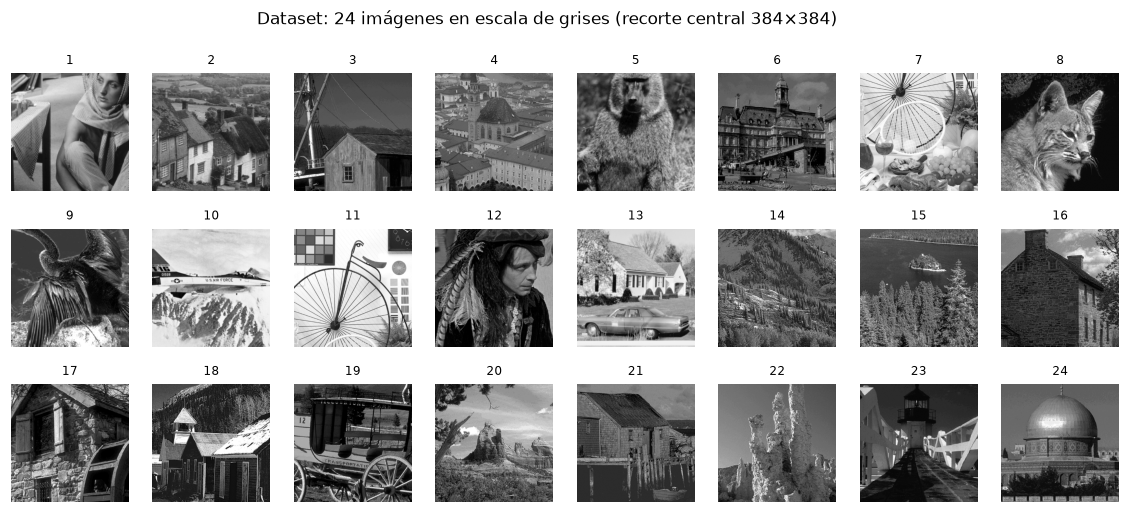

In [2]:
def load_dataset(data_dir, n_images=24, size=384):
    # Carga k.gif (k=1..n), normaliza a [0,1] (mat2gray) y recorta el centro size x size.
    images = []
    for k in range(1, n_images + 1):
        img = np.asarray(Image.open(data_dir / f"{k}.gif").convert("L"), dtype=np.float64)
        img = (img - img.min()) / (img.max() - img.min())          # mat2gray
        d1, d2 = img.shape
        r0, c0 = (d1 - size) // 2, (d2 - size) // 2
        images.append(img[r0:r0 + size, c0:c0 + size])
    return np.stack(images)

dataset = load_dataset(DATA_DIR, N_IMAGES, M)
print("dataset:", dataset.shape, dataset.dtype, f"rango [{dataset.min():.2f}, {dataset.max():.2f}]")

fig, axes = plt.subplots(3, 8, figsize=(13, 5.2))
for k, ax in enumerate(axes.flat):
    ax.imshow(dataset[k], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{k + 1}", fontsize=8); ax.axis("off")
fig.suptitle("Dataset: 24 imágenes en escala de grises (recorte central 384×384)")
fig.savefig(FIG_DIR / "dataset.png"); plt.show()

### 2.2 Importancia de la fase

Como en la Fig. 1 del enunciado (Oppenheim & Lim, 1981), se intercambian las fases de Fourier de dos imágenes
del dataset: $\mathcal F^{-1}\{|\mathcal F\{a\}|\,e^{i\angle\mathcal F\{b\}}\}$. La imagen resultante se parece a
la imagen que aporta la **fase**, no a la que aporta la magnitud. Por eso perder la fase en el sensor
(Ec. 3) es tan grave y es necesario recuperarla.

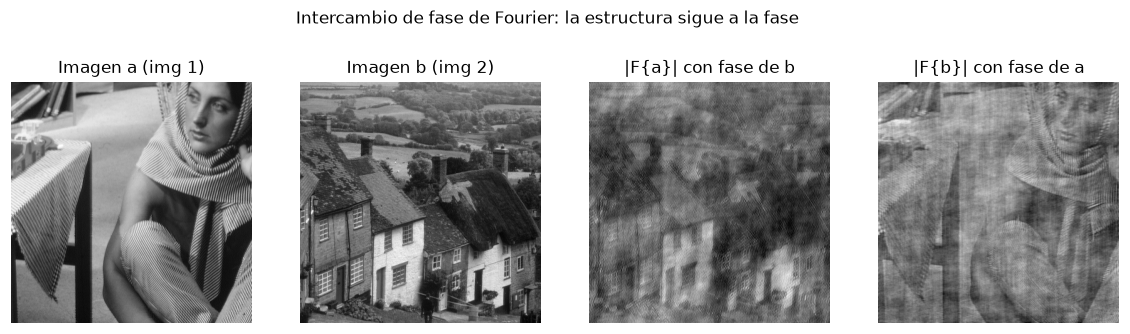

In [3]:
def swap_fourier_phase(a, b):
    # Magnitud de a con fase de b, y viceversa.
    Fa, Fb = np.fft.fft2(a), np.fft.fft2(b)
    ab = np.real(np.fft.ifft2(np.abs(Fa) * np.exp(1j * np.angle(Fb))))
    ba = np.real(np.fft.ifft2(np.abs(Fb) * np.exp(1j * np.angle(Fa))))
    return ab, ba

img_a, img_b = dataset[0], dataset[1]
mag_a_ph_b, mag_b_ph_a = swap_fourier_phase(img_a, img_b)
norm = lambda x: (x - x.min()) / (x.max() - x.min())
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
for ax, (im, title) in zip(axes, [(img_a, "Imagen a (img 1)"), (img_b, "Imagen b (img 2)"),
                                  (norm(mag_a_ph_b), "|F{a}| con fase de b"), (norm(mag_b_ph_a), "|F{b}| con fase de a")]):
    ax.imshow(im, cmap="gray"); ax.set_title(title); ax.axis("off")
fig.suptitle("Intercambio de fase de Fourier: la estructura sigue a la fase")
fig.savefig(FIG_DIR / "phase_swap.png"); plt.show()

## 3. Implementación del forward model

### 3.1 Port literal de `ang_spec_multi_prop.m` (Schmidt, 2010)

Las funciones `ft2`/`ift2` son la DFT 2D centrada de Schmidt, escalada por $\delta^2$ y $(N\,\delta f)^2$.
La propagación multi-paso aplica, entre planos consecutivos $z_i\to z_{i+1}$, la función de transferencia
$Q_2=\exp\!\big(i\pi^2\,2\Delta z_i/(m_i k)\,f^2\big)$. Los factores cuadráticos de entrada y salida
($Q_1$, $Q_3$) solo intervienen cuando $\delta_1\neq\delta_n$ (cambio de escala $m\neq1$). También se porta
`ang_spec_pro.m` (un solo paso) para verificar la consistencia.

> Nota: en el repositorio, `Q3` usa `m(end-1)` y, en el libro de Schmidt, `m(n-1)`, que es el **último**
> elemento de `m`. Aquí se sigue al libro (`m[-1]`). Con $\delta_1=\delta_n$ ($m\equiv1$) ambas versiones son idénticas.

In [4]:
def ft2(g, dx):
    # DFT 2D centrada (Schmidt): fftshift(fft2(fftshift(g))) * dx^2
    return sfft.fftshift(sfft.fft2(sfft.fftshift(g, axes=(-2, -1))), axes=(-2, -1)) * dx**2

def ift2(G, df):
    # IDFT 2D centrada (Schmidt): ifftshift(ifft2(ifftshift(G))) * (N df)^2
    N = G.shape[-1]
    return sfft.ifftshift(sfft.ifft2(sfft.ifftshift(G, axes=(-2, -1))), axes=(-2, -1)) * (N * df)**2

def ang_spec_pro(Uin, wvl, d1, d2, Dz):
    # Port de ang_spec_pro.m: propagación por espectro angular en un paso.
    N = Uin.shape[-1]
    k = 2 * np.pi / wvl
    n = np.arange(-N // 2, N // 2)
    x1, y1 = np.meshgrid(n * d1, n * d1); r1sq = x1**2 + y1**2
    df1 = 1 / (N * d1)
    fX, fY = np.meshgrid(n * df1, n * df1); fsq = fX**2 + fY**2
    m = d2 / d1
    x2, y2 = np.meshgrid(n * d2, n * d2); r2sq = x2**2 + y2**2
    Q1 = np.exp(-1j * k / 2 * (1 - m) / Dz * r1sq)
    Q2 = np.exp(1j * np.pi**2 * 2 * Dz / m / k * fsq)
    Q3 = np.exp(-1j * k / 2 * (m - 1) / (m * Dz) * r2sq)
    return Q3 * ift2(Q2 * ft2(Q1 * Uin / m, d1), df1)

def ang_spec_multi_prop(Uin, wvl, delta1, deltan, z):
    # Port literal de ang_spec_multi_prop.m (split-step, sin absorbente: sg = 1).
    z = np.asarray(z, dtype=float)
    N = Uin.shape[-1]
    n = np.arange(-N // 2, N // 2)
    nx, ny = np.meshgrid(n, n)
    k = 2 * np.pi / wvl
    delta_z = np.diff(z)
    alpha = z / z[-1]
    delta = (1 - alpha) * delta1 + alpha * deltan
    m = delta[1:] / delta[:-1]
    r1sq = (nx * delta[0])**2 + (ny * delta[0])**2
    U = Uin * np.exp(-1j * k / 2 * (1 - m[0]) / delta_z[0] * r1sq)
    for idx in range(len(z) - 1):
        deltaf = 1 / (N * delta[idx])
        fsq = (nx * deltaf)**2 + (ny * deltaf)**2
        Q2 = np.exp(1j * np.pi**2 * 2 * delta_z[idx] / m[idx] / k * fsq)
        U = ift2(Q2 * ft2(U / m[idx], delta[idx]), deltaf)
    rnsq = (nx * delta[-1])**2 + (ny * delta[-1])**2
    Q3 = np.exp(-1j * k / 2 * (m[-1] - 1) / (m[-1] * delta_z[-1]) * rnsq)
    return Q3 * U

### 3.2 Propagador eficiente (precalculado y equivalente)

En HIO el propagador se evalúa $2L$ veces por iteración, por lo que conviene precalcularlo. Hay dos
simplificaciones **exactas** (no son aproximaciones):

* Entre pasos consecutivos, `ift2(·, δf_i)` seguida de `ft2(·, δ_{i+1})` se cancela salvo un escalar, así
  que los $Q_2$ de los 4 pasos se combinan en una sola función de transferencia
  $H=\prod_i Q_2^{(i)}$, con factor $\prod_i 1/m_i$.
* Los `fftshift` alrededor de un operador de convolución circular se cancelan para $N$ par.

La clase `NearFieldPropagator` aplica entonces $\mathcal{P}[\Delta z]\{U\}=Q_3\,\mathcal{F}^{-1}\{H\,\mathcal{F}\{Q_1 U\}\}$,
con 2 FFT en lugar de 8, y opera en lote sobre un arreglo `(L, M, M)`. Igual que en `PhaseLiftSimu.m`,
la retropropagación $\mathcal{P}^{-1}$ se obtiene llamando al mismo propagador con `-z`.

In [5]:
class NearFieldPropagator:
    # P[Δz] por espectro angular multi-paso (Schmidt), precalculado. Acepta (..., N, N).
    def __init__(self, N, wvl, delta1, deltan, z):
        z = np.asarray(z, dtype=float)
        k = 2 * np.pi / wvl
        n = np.arange(-N // 2, N // 2)
        nx, ny = np.meshgrid(n, n)
        nsq = (nx**2 + ny**2).astype(float)
        dz = np.diff(z)
        alpha = z / z[-1]
        delta = (1 - alpha) * delta1 + alpha * deltan
        m = delta[1:] / delta[:-1]
        H = np.ones((N, N), dtype=complex)
        scale = 1.0
        for i in range(len(dz)):
            df = 1 / (N * delta[i])
            H *= np.exp(1j * np.pi**2 * 2 * dz[i] / m[i] / k * nsq * df**2)
            scale /= m[i]
        self.Q1 = np.exp(-1j * k / 2 * (1 - m[0]) / dz[0] * nsq * delta[0]**2)
        self.Q3 = np.exp(-1j * k / 2 * (m[-1] - 1) / (m[-1] * dz[-1]) * nsq * delta[-1]**2)
        self.trivial_quadratic = np.allclose(m, 1.0)      # Q1 = Q3 = 1 si delta1 == deltan
        self.H = sfft.ifftshift(H) * scale                # H en orden "no centrado" de la FFT

    def __call__(self, U):
        if self.trivial_quadratic:
            return sfft.ifft2(self.H * sfft.fft2(U, workers=-1), workers=-1)
        U = sfft.ifftshift(self.Q1 * U, axes=(-2, -1))
        U = sfft.ifft2(self.H * sfft.fft2(U, workers=-1), workers=-1)
        return self.Q3 * sfft.fftshift(U, axes=(-2, -1))

prop_fwd = NearFieldPropagator(M, WVL, DELTA1, DELTAN, Z)     # P[Δz]
prop_bwd = NearFieldPropagator(M, WVL, DELTA1, DELTAN, -Z)    # P[-Δz]  (como propagation(..., -z))

### 3.3 Verificaciones numéricas del propagador

Antes de usarlo dentro de HIO se verifica que:

1. el propagador rápido coincide con el port literal (y con el de un solo paso, `ang_spec_pro`);
2. también coincide en el caso general $\delta_1\neq\delta_n$;
3. conserva la energía (operador unitario, Parseval), condición necesaria para que HIO sea estable;
4. $\mathcal{P}[-\Delta z]\,\mathcal{P}[\Delta z] = \mathbf{I}$ a precisión de máquina (forward/backward estable);
5. se cumple el criterio de muestreo $N\ge\lambda\Delta z/\delta^2$.

In [6]:
rng_test = np.random.default_rng(0)
U_test = rng_test.random((M, M)) * np.exp(1j * rng_test.random((M, M)))
rel = lambda a, b: np.abs(a - b).max() / np.abs(b).max()

lit_f = ang_spec_multi_prop(U_test, WVL, DELTA1, DELTAN, Z)
lit_b = ang_spec_multi_prop(U_test, WVL, DELTA1, DELTAN, -Z)
one_step = ang_spec_pro(U_test, WVL, DELTA1, DELTAN, Z[-1])
gen = NearFieldPropagator(M, WVL, 0.02, 0.03, Z)(U_test)
gen_lit = ang_spec_multi_prop(U_test, WVL, 0.02, 0.03, Z)

print(f"1) rápido vs literal (forward)        : {rel(prop_fwd(U_test), lit_f):.2e}")
print(f"   rápido vs literal (backward)       : {rel(prop_bwd(U_test), lit_b):.2e}")
print(f"   multi-paso vs un paso (ang_spec_pro): {rel(lit_f, one_step):.2e}")
print(f"2) rápido vs literal, δ1=0.02, δn=0.03 : {rel(gen, gen_lit):.2e}")
print(f"3) ||P{{U}}|| / ||U||                   : {np.linalg.norm(prop_fwd(U_test)) / np.linalg.norm(U_test):.15f}")
print(f"4) max |P^-1 P U - U|                 : {np.abs(prop_bwd(prop_fwd(U_test)) - U_test).max():.2e}")
N_min = WVL * Z[-1] / DELTA1**2
print(f"5) N mínimo = λΔz/δ² = {N_min:.1f}  ->  N=256 {'OK' if 256 >= N_min else 'aliasing'} | N={M} {'OK' if M >= N_min else 'aliasing'}")

t0 = time.perf_counter(); _ = prop_fwd(np.tile(U_test, (16, 1, 1))); t1 = time.perf_counter()
_ = ang_spec_multi_prop(np.tile(U_test, (16, 1, 1)), WVL, DELTA1, DELTAN, Z); t2 = time.perf_counter()
print(f"Tiempo propagando 16 campos: rápido {1e3 * (t1 - t0):.1f} ms vs literal {1e3 * (t2 - t1):.1f} ms")

1) rápido vs literal (forward)        : 1.78e-14
   rápido vs literal (backward)       : 1.60e-14
   multi-paso vs un paso (ang_spec_pro): 9.84e-16
2) rápido vs literal, δ1=0.02, δn=0.03 : 8.17e-14
3) ||P{U}|| / ||U||                   : 1.000000000000001
4) max |P^-1 P U - U|                 : 1.05e-15
5) N mínimo = λΔz/δ² = 257.2  ->  N=256 aliasing | N=384 OK


Tiempo propagando 16 campos: rápido 20.7 ms vs literal 229.4 ms


## 4. Generación de máscaras aleatorias complementarias

Port de `selectMasks.m` (`codes = 1`, `complementary = 1`) y de `complementary_masks.m`:

* se generan $L$ máscaras binarias i.i.d. `rand(M,N) > 0.5`;
* `complementary_masks` toma la $c$-ésima máscara aleatoria como máscara impar $2c-1$ y define la par como
  su complemento booleano: $\mathbf{A}_{2c}=\neg\mathbf{A}_{2c-1}$.

En consecuencia, cada par cubre todo el plano ($\mathbf{A}_{2c-1}+\mathbf{A}_{2c}=\mathbf{1}$) y
$\sum_\ell\mathbf{A}_\ell = L/2$ en todos los píxeles. También se porta `ComputeConditionNumber.m`
($\kappa(\mathbf{K}^T\mathbf{K})$, con $\mathbf{K}\in\{0,1\}^{d^2\times L}$ formada por las máscaras vectorizadas).

In [7]:
def complementary_masks(masks):
    # Port de complementary_masks.m: T(:,:,i) = masks(:,:,c); T(:,:,i+1) = ~T(:,:,i).
    L = masks.shape[0]
    assert L % 2 == 0, "L debe ser par para máscaras complementarias por pares"
    T = np.empty_like(masks)
    T[0::2] = masks[: L // 2]
    T[1::2] = 1.0 - T[0::2]
    return T

def select_masks(L, M, rng, complementary=True):
    # Port de selectMasks.m para codes == 1 (máscaras aleatorias).
    masks = (rng.random((L, M, M)) > 0.5).astype(np.float64)
    return complementary_masks(masks) if complementary else masks

def compute_condition_number(T):
    # Port de ComputeConditionNumber.m: cond(K' * K), K = [vec(A_1) ... vec(A_L)].
    K = T.reshape(T.shape[0], -1).T
    return np.linalg.cond(K.T @ K)

masks_by_L = {L: select_masks(L, M, np.random.default_rng(SEED + L)) for L in L_LIST}
for L, A in masks_by_L.items():
    pair_sum = A[0::2] + A[1::2]
    print(f"L={L:2d}: shape={A.shape}, fracción de 1s={A.mean():.3f}, "
          f"pares complementarios: {np.all(pair_sum == 1)}, "
          f"Σ_l A_l = {np.unique(A.sum(0))}, κ(KᵀK) = {compute_condition_number(A):.2e}, "
          f"rango(KᵀK) = {np.linalg.matrix_rank(A.reshape(L, -1) @ A.reshape(L, -1).T)}")

L= 4: shape=(4, 384, 384), fracción de 1s=0.500, pares complementarios: True, Σ_l A_l = [2.], κ(KᵀK) = 1.89e+17, rango(KᵀK) = 3
L=16: shape=(16, 384, 384), fracción de 1s=0.500, pares complementarios: True, Σ_l A_l = [8.], κ(KᵀK) = 1.71e+18, rango(KᵀK) = 9


**Nota sobre el número de condición.** Con pares complementarios, $\mathbf{A}_{2c-1}+\mathbf{A}_{2c}=\mathbf 1$
para todo $c$, así que las columnas de $\mathbf K$ satisfacen $L/2-1$ relaciones lineales
($\mathbf A_1+\mathbf A_2-\mathbf A_3-\mathbf A_4=\mathbf 0$, …). Por eso
$\operatorname{rango}(\mathbf K^T\mathbf K)=L/2+1$ y $\kappa(\mathbf K^T\mathbf K)$ es, en la práctica, infinito
(~10¹⁷, que es el límite de precisión). Esa métrica lineal no refleja el condicionamiento del problema de phase retrieval,
que es no lineal (cuadrático en $\mathbf O$). Lo relevante aquí es que cada píxel queda cubierto exactamente
$L/2$ veces.

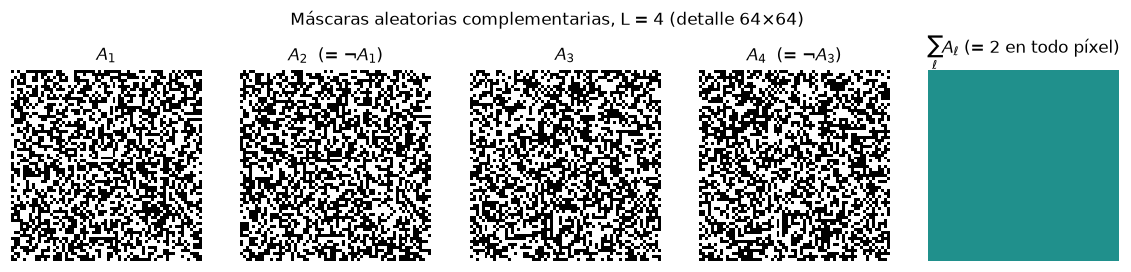

In [8]:
A4 = masks_by_L[4]
fig, axes = plt.subplots(1, 5, figsize=(13, 2.9))
for l in range(4):
    axes[l].imshow(A4[l, :64, :64], cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    axes[l].set_title(f"$A_{l + 1}$" + ("  (= ¬$A_{%d}$)" % l if l % 2 else ""))
axes[4].imshow(A4.sum(0)[:64, :64], cmap="viridis", vmin=0, vmax=4, interpolation="nearest")
axes[4].set_title(r"$\sum_\ell A_\ell$ (= 2 en todo píxel)")
for ax in axes: ax.axis("off")
fig.suptitle("Máscaras aleatorias complementarias, L = 4 (detalle 64×64)")
fig.savefig(FIG_DIR / "masks_L4.png"); plt.show()

## 5. Simulación de las mediciones

Para la imagen $k=1,\dots,24$, se usa la imagen $k$ como **fase** y la imagen $25-k$ como **amplitud**, igual
que en `main.m` (`intensity = dataset(:,:,25-k); phase = dataset(:,:,k)`). Así, cada una de las 24
imágenes se usa tanto como amplitud como fase. La fase queda en $[0,1]$ rad, como en el código de
referencia, por lo que no hay *wrapping*.

$$\mathbf{O}_k = \mathbf{x}_{25-k}\odot e^{i\,\mathbf{x}_k},\qquad
\mathbf{Y}_\ell = |\mathcal{P}[\Delta z]\{\mathbf{A}_\ell\odot\mathbf{O}_k\}|^2 + \boldsymbol{\Omega}_\ell .$$

**Ruido $\boldsymbol\Omega$.** Ruido gaussiano aditivo real, i.i.d., con desviación estándar fijada por un
SNR por objeto: $\sigma^2 = \overline{|\mathbf{I}|^4}/10^{\mathrm{SNR}/10}$, con semilla fija. Las mediciones
ruidosas pueden ser ligeramente negativas; el algoritmo usa $\sqrt{\max(\mathbf{Y}_\ell,0)}$.

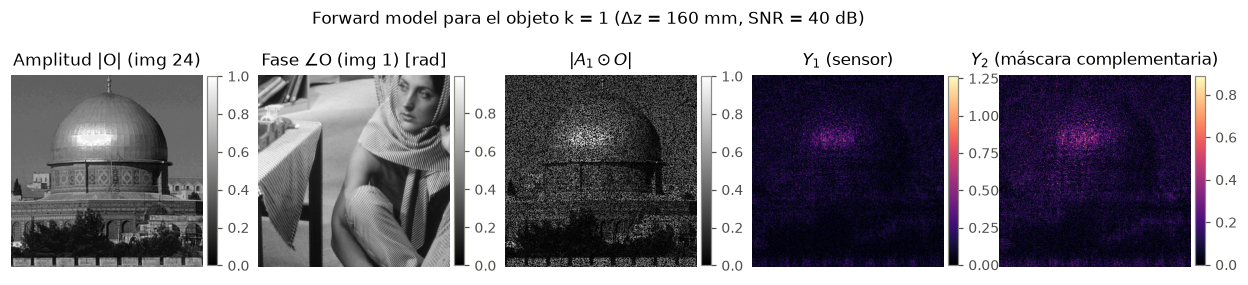

In [9]:
def make_object(dataset, k):
    # k en 1..24: fase = imagen k, amplitud = imagen 25-k (como en main.m).
    amplitude = dataset[(25 - k) - 1]
    phase = dataset[k - 1]
    return amplitude, phase, amplitude * np.exp(1j * phase)

def simulate_measurements(O, masks, prop, snr_db=None, rng=None):
    # Y_l = |P[Δz]{A_l ⊙ O}|^2 + Ω_l  (vectorizado sobre l).
    Y = np.abs(prop(masks * O[None])) ** 2
    if snr_db is not None:
        sigma = np.sqrt(np.mean(Y**2) / 10 ** (snr_db / 10))
        Y = Y + sigma * rng.standard_normal(Y.shape)
    return Y

amp_ex, ph_ex, O_ex = make_object(dataset, 1)
Y_ex = simulate_measurements(O_ex, masks_by_L[4], prop_fwd, SNR_DB, np.random.default_rng(0))
fig, axes = plt.subplots(1, 5, figsize=(14, 3.0))
panels = [(amp_ex, "Amplitud |O| (img 24)", "gray"), (ph_ex, "Fase ∠O (img 1) [rad]", "gray"),
          (np.abs(masks_by_L[4][0] * O_ex), r"$|A_1\odot O|$", "gray"),
          (Y_ex[0], r"$Y_1$ (sensor)", "magma"), (Y_ex[1], r"$Y_2$ (máscara complementaria)", "magma")]
for ax, (im, title, cmap) in zip(axes, panels):
    h = ax.imshow(im, cmap=cmap); ax.set_title(title); ax.axis("off")
    fig.colorbar(h, ax=ax, fraction=0.046, pad=0.02)
fig.suptitle(f"Forward model para el objeto k = 1 (Δz = {Z[-1]:.0f} mm, SNR = {SNR_DB} dB)")
fig.savefig(FIG_DIR / "forward_example.png"); plt.show()

## 6. Algoritmo Hybrid Input–Output (HIO)

### 6.1 HIO clásico (Fienup, 1982)

HIO alterna entre dos dominios. En la iteración $k$, con estimación $g_k$ en el plano objeto:

1. **Restricción del dominio de medición** (proyección $P_M$): se propaga
   $G_k=\mathcal{P}[\Delta z]\{g_k\}$, se reemplaza la magnitud por la medida conservando la fase
   estimada, $G'_k=\sqrt{\mathbf{Y}}\,e^{i\angle G_k}$, y se retropropaga: $g'_k=\mathcal{P}^{-1}\{G'_k\}$.
2. **Restricción del dominio objeto**, con $\gamma$ como la región donde $g'_k$ cumple las restricciones
   (soporte, no negatividad, etc.):
$$
g_{k+1}(x) = \begin{cases} g'_k(x), & x\in\gamma \quad\text{(región válida)}\\[2pt]
g_k(x) - \beta\, g'_k(x), & x\notin\gamma \quad\text{(región que viola la restricción)}\end{cases}
$$

Con $\beta=0$ fuera del soporte y $g'_k$ dentro se obtiene **Error Reduction (ER)**, es decir,
Gerchberg–Saxton/Fienup. ER es el esquema que implementa `PhaseLiftSimu.m`. El término de realimentación
$-\beta g'_k$ es lo que permite a HIO escapar de estancamientos de ER.

### 6.2 Extensión a $L$ máscaras codificadas

Con iluminación codificada, la restricción del dominio objeto se aplica a las **ondas de salida**
$\boldsymbol\psi_\ell = \mathbf{A}_\ell\odot\mathbf{O}$. Para cada máscara, el soporte es
$\{x:\mathbf{A}_\ell(x)=1\}$, y además las $L$ ondas deben provenir del **mismo** objeto $\mathbf{O}$. El
conjunto de restricciones es

$$\mathcal{S}=\{(\boldsymbol\psi_1,\dots,\boldsymbol\psi_L):\ \boldsymbol\psi_\ell=\mathbf{A}_\ell\odot\mathbf{O}\ \ \text{para algún }\mathbf{O}\},$$

y su proyección ortogonal (mínimos cuadrados) es

$$\hat{\mathbf{O}} = \frac{\sum_\ell \mathbf{A}_\ell\odot\boldsymbol\psi_\ell}{\sum_\ell\mathbf{A}_\ell},\qquad
P_{\mathcal S}(\boldsymbol\psi)_\ell = \mathbf{A}_\ell\odot\hat{\mathbf{O}}.$$

Con máscaras complementarias, $\sum_\ell\mathbf{A}_\ell=L/2>0$ en todo píxel, así que la división siempre está
bien definida. Esta es una ventaja directa de usar pares complementarios.

Como $P_\mathcal{S}$ es lineal, la regla de HIO se escribe de forma compacta (Bauschke, Combettes & Luke, 2002):

$$\boxed{\;g_{k+1} = P_\mathcal{S}(g'_k) + (I-P_\mathcal{S})\,(g_k-\beta\,g'_k),\qquad g'_k = P_M(g_k)\;}$$

* **Dentro de la región válida** (la componente de $g'_k$ en $\mathcal S$, es decir, en el soporte de
  $\mathbf{A}_\ell$ y consistente entre máscaras) se usa directamente la estimación actualizada $g'_k$.
* **Fuera** (energía de $g'_k$ fuera del soporte $\mathbf{A}_\ell=0$ o inconsistencias entre máscaras),
  se aplica $g_k-\beta g'_k$.
* Para $L=1$ y $P_\mathcal S$ igual a una proyección de soporte, esta regla es **exactamente** el HIO
  clásico de 6.1.

En cada pasada se recorren las $L$ máscaras. El paso $P_M$ se aplica a cada $\mathbf{Y}_\ell$ con su onda
$\boldsymbol\psi_\ell$; el bucle sobre $\ell$ está vectorizado sobre el primer eje del arreglo
`(L, M, M)`, de modo que las $L$ FFT se ejecutan en lote.

**Métrica de convergencia.** Se usa el error del dominio objeto de Fienup,
$E_k = \|(I-P_\mathcal S)g'_k\|/\|g'_k\|$, que es la fracción de energía que viola las restricciones. Vale 0
en una solución exacta y no requiere conocer el *ground truth*.

### 6.3 Alternancia HIO/ER (robustez al ruido)

Con mediciones ruidosas no existe un objeto que satisfaga simultáneamente todas las restricciones
($\mathcal M\cap\mathcal S=\emptyset$). En ese caso, el término $(I-P_\mathcal S)(g_k-\beta g'_k)$ de HIO
**acumula** en cada iteración la parte de $g'_k$ que no puede anularse, y el iterado se aleja de la solución
(se observa en la Sección 8: HIO puro diverge). Fienup recomienda alternar ciclos de HIO con ciclos de ER.
Aquí se usan bloques de `hio_block` iteraciones HIO seguidos de `er_block` iteraciones ER
($g_{k+1}=P_\mathcal S(g'_k)$). Cada bloque ER devuelve el iterado al conjunto $\mathcal S$ y descarta la
realimentación acumulada, mientras que los bloques HIO aportan la capacidad de escapar de estancamientos.
Con `er_block = 0` se recupera HIO puro.

**Inicialización.** Igual que en `main.m` (`fieldvec = ones(M,N)`): objeto constante, escalado para que
su energía coincida con la medida. Las máscaras son binarias y la propagación es unitaria, por lo que
$\sum_\ell\|\mathbf{Y}_\ell\|_1 = \sum_\ell\|\mathbf{A}_\ell\odot\mathbf{O}\|_2^2$.

In [10]:
def hio_schedule(n_iter, hio_block=10, er_block=10):
    # True = iteración HIO, False = iteración ER. Ciclos [hio_block x HIO, er_block x ER].
    if er_block == 0:
        return np.ones(n_iter, dtype=bool)
    cycle = np.r_[np.ones(hio_block, bool), np.zeros(er_block, bool)]
    return np.resize(cycle, n_iter)

def hio_reconstruct(Y_list, masks, prop_fwd, prop_bwd, n_iter=100, beta=0.9, hio_block=10, er_block=10,
                    O_init=None, callback=None, return_history=False):
    # Hybrid Input-Output para phase retrieval con L aperturas codificadas.
    # Y_list: (L, M, M) mediciones; masks: (L, M, M) máscaras binarias.
    # n_iter iteraciones totales, en ciclos de hio_block HIO + er_block ER (er_block=0 -> HIO puro).
    # callback(it, O_hat) opcional. Retorna O_hat (M, M) complejo y, si return_history, E_k.
    Y = np.asarray(Y_list, dtype=float)
    A = np.asarray(masks, dtype=float)
    sqrtY = np.sqrt(np.maximum(Y, 0.0))                    # magnitud medida (ruido -> Y < 0)
    weight = A.sum(axis=0)                                 # Σ_l A_l  (= L/2 si complementarias)
    if np.any(weight == 0):
        raise ValueError("Hay píxeles no iluminados por ninguna máscara.")

    if O_init is None:                                     # fieldvec = ones(M,N), con energía correcta
        O_init = np.full(A.shape[1:], np.sqrt(Y.sum() / weight.sum()), dtype=complex)
    g = A * O_init[None]                                   # ondas de salida ψ_l = A_l ⊙ O
    schedule = hio_schedule(n_iter, hio_block, er_block)
    history = np.empty(n_iter)

    for it in range(n_iter):
        # --- (1) Restricción de medición P_M, para las L máscaras -------------------
        G = prop_fwd(g)                                    # P[Δz]{ψ_l}
        G_new = sqrtY * G / np.maximum(np.abs(G), 1e-30)   # √Y_l · exp(i∠G_l)
        g_prime = prop_bwd(G_new)                          # P[-Δz]{·}  -> g'_k

        # --- (2) Restricción de objeto: proyección P_S (soporte + consistencia) ------
        O_hat = (A * g_prime).sum(axis=0) / weight         # objeto consenso
        PS_gp = A * O_hat[None]                            # P_S(g'_k)   (región válida)
        violation = g_prime - PS_gp                        # (I - P_S) g'_k
        history[it] = np.linalg.norm(violation) / np.linalg.norm(g_prime)

        if schedule[it]:                                   # HIO
            PS_g = A * ((A * g).sum(axis=0) / weight)[None]
            g = PS_gp + (g - PS_g) - beta * violation      # P_S g' + (I-P_S)(g - β g')
        else:                                              # ER: g = P_S(g')
            g = PS_gp
        if callback is not None:
            callback(it, O_hat)

    return (O_hat, history) if return_history else O_hat

**Prueba rápida de sanidad** (objeto $k=1$, $L=4$): el error $E_k$ debe decrecer de forma monótona en
promedio y la reconstrucción debe parecerse visualmente al objeto.

In [11]:
t0 = time.perf_counter()
O_sanity, hist_sanity = hio_reconstruct(Y_ex, masks_by_L[4], prop_fwd, prop_bwd,
                                        n_iter=50, beta=BETA, hio_block=HIO_BLOCK, er_block=ER_BLOCK,
                                        return_history=True)
print(f"50 iteraciones en {time.perf_counter() - t0:.2f} s;  E_1 = {hist_sanity[0]:.3e}  ->  E_50 = {hist_sanity[-1]:.3e}")

50 iteraciones en 0.61 s;  E_1 = 2.153e-01  ->  E_50 = 2.015e-02


## 7. Métricas de calidad: PSNR y SSIM

**PSNR** (dB):

$$\mathrm{PSNR} = 10\log_{10}\!\left(\frac{\mathrm{MAX}_I^2}{\mathrm{MSE}}\right),\qquad (5)$$

$$\mathrm{MSE} = \frac{1}{m\,n}\sum_{i=0}^{m-1}\sum_{j=0}^{n-1}\big[I(i,j)-K(i,j)\big]^2 .\qquad (6)$$

**SSIM**:

$$\mathrm{SSIM}(x,y) = \frac{(2\mu_x\mu_y + C_1)(2\sigma_{xy}+C_2)}{(\mu_x^2+\mu_y^2+C_1)(\sigma_x^2+\sigma_y^2+C_2)},\qquad (7)$$

donde $\mu$, $\sigma^2$ y $\sigma_{xy}$ son medias, varianzas y covarianza **locales**, y
$C_1=(K_1 L)^2$, $C_2=(K_2 L)^2$.

**Relación con el código**

* `psnr_eq` implementa literalmente las Ecs. (5)–(6). Como las imágenes están en $[0,1]$ (`float`),
  $\mathrm{MAX}_I = 1$ (equivale a 255 en 8 bits). Se verifica que coincide con
  `skimage.metrics.peak_signal_noise_ratio(..., data_range=1)`.
* `ssim_eq` implementa la Ec. (7). Las estadísticas locales se calculan con una ventana gaussiana
  $\sigma=1.5$ (como `ssim` de MATLAB y Wang et al., 2004): $\mu_x = w * x$,
  $\sigma_x^2 = w*x^2-\mu_x^2$, $\sigma_{xy}=w*(xy)-\mu_x\mu_y$, con $K_1=0.01$, $K_2=0.03$ y rango dinámico
  $L=1$. El índice final es el promedio del mapa SSIM local (excluyendo el borde de la ventana). Se verifica
  que coincide con `skimage.metrics.structural_similarity(..., gaussian_weights=True, sigma=1.5,
  use_sample_covariance=False)`, que es la función usada en los experimentos.

**Ambigüedad de fase global.** $\mathbf{O}$ y $\mathbf{O}e^{i\theta}$ generan las mismas mediciones, así que
antes de evaluar se elimina la fase global de la reconstrucción:
$\hat{\mathbf{O}}\leftarrow\hat{\mathbf{O}}\,e^{-i\theta^\star}$ con $\theta^\star=\angle\langle\mathbf{O},\hat{\mathbf{O}}\rangle$.
Esto es estándar en phase retrieval. Después se comparan $|\hat{\mathbf O}|$ con la amplitud real y
$\angle\hat{\mathbf O}$ con la fase real, ambas recortadas al rango $[0,1]$ del *ground truth*. (`main.m`
usa, en cambio, `mat2gray` sobre la reconstrucción; eso también compensa el desfase, pero distorsiona el
rango cuando hay valores extremos en zonas oscuras).

**Observación importante.** Donde la amplitud real es ≈ 0, la fase no está definida físicamente y no se
puede recuperar. Las imágenes normalizadas con `mat2gray` tienen píxeles con amplitud exactamente 0, por
lo que la PSNR de fase queda acotada aunque la amplitud se recupere perfectamente.

In [12]:
def psnr_eq(I, K, max_i=1.0):
    # Ecs. (5)-(6).
    mse = np.mean((I.astype(float) - K.astype(float)) ** 2)
    return np.inf if mse == 0 else 10 * np.log10(max_i**2 / mse)

def ssim_eq(x, y, data_range=1.0, K1=0.01, K2=0.03, sigma=1.5, truncate=3.5):
    # Ec. (7) con ventana gaussiana (estadísticos poblacionales), promedio del mapa SSIM.
    x = x.astype(float); y = y.astype(float)
    w = lambda img: gaussian_filter(img, sigma=sigma, truncate=truncate, mode="reflect")
    mu_x, mu_y = w(x), w(y)
    var_x = w(x * x) - mu_x**2
    var_y = w(y * y) - mu_y**2
    cov_xy = w(x * y) - mu_x * mu_y
    C1, C2 = (K1 * data_range) ** 2, (K2 * data_range) ** 2
    S = ((2 * mu_x * mu_y + C1) * (2 * cov_xy + C2)) / ((mu_x**2 + mu_y**2 + C1) * (var_x + var_y + C2))
    pad = int(truncate * sigma + 0.5)                      # borde de la ventana (11x11)
    return S[pad:-pad, pad:-pad].mean()

def ssim_sk(x, y):
    return structural_similarity(x, y, data_range=1.0, gaussian_weights=True, sigma=1.5,
                                 use_sample_covariance=False)

def align_global_phase(O_hat, O_true):
    # Elimina la ambigüedad de fase global: O_hat * exp(-i θ*), θ* = ∠<O_true, O_hat>.
    return O_hat * np.exp(-1j * np.angle(np.vdot(O_true, O_hat)))

def evaluate(O_hat, amplitude, phase):
    O_al = align_global_phase(O_hat, amplitude * np.exp(1j * phase))
    amp_hat = np.clip(np.abs(O_al), 0, 1)
    ph_hat = np.clip(np.angle(O_al), 0, 1)
    return {
        "psnr_amp": peak_signal_noise_ratio(amplitude, amp_hat, data_range=1.0),
        "ssim_amp": ssim_sk(amplitude, amp_hat),
        "psnr_ph": peak_signal_noise_ratio(phase, ph_hat, data_range=1.0),
        "ssim_ph": ssim_sk(phase, ph_hat),
    }, amp_hat, ph_hat

# Verificación: implementaciones propias (Ecs. 5-7) vs scikit-image
amp_s = np.clip(np.abs(align_global_phase(O_sanity, O_ex)), 0, 1)
print(f"PSNR  Ec.(5-6) = {psnr_eq(amp_ex, amp_s):.6f} dB | skimage = {peak_signal_noise_ratio(amp_ex, amp_s, data_range=1.0):.6f} dB")
print(f"SSIM  Ec.(7)   = {ssim_eq(amp_ex, amp_s):.6f}    | skimage = {ssim_sk(amp_ex, amp_s):.6f}")
m_s, _, _ = evaluate(O_sanity, amp_ex, ph_ex)
print("Sanidad (k=1, L=4, 50 it):", {k: round(v, 3) for k, v in m_s.items()})

PSNR  Ec.(5-6) = 44.457036 dB | skimage = 44.457036 dB
SSIM  Ec.(7)   = 0.984973    | skimage = 0.984973
Sanidad (k=1, L=4, 50 it): {'psnr_amp': np.float64(44.457), 'ssim_amp': np.float64(0.985), 'psnr_ph': np.float64(27.027), 'ssim_ph': np.float64(0.841)}


## 8. Selección de $\beta$ y del número de iteraciones

Antes de los experimentos completos se hace un estudio pequeño con 3 objetos ($k=1, 8, 16$), $L=4$ (el
caso con menos mediciones) y 200 iteraciones. Se comparan:

* **ER** puro (equivalente, en paralelo, al esquema de `PhaseLiftSimu.m`);
* **HIO puro** con $\beta=0.9$;
* **HIO/ER** (bloques 10+10) con $\beta\in\{0.5, 0.7, 0.9\}$.

Para cada configuración se registra, en cada iteración, $E_k$ y la PSNR de amplitud y de fase. Con esto se
eligen $\beta$, el esquema y un número de iteraciones **fijo**, igual para $L=4$ y $L=16$, de modo que la
comparación sea justa.

In [13]:
def run_one(k, L, n_iter, beta, hio_block=HIO_BLOCK, er_block=ER_BLOCK, snr_db=SNR_DB, track=False):
    amplitude, phase, O = make_object(dataset, k)
    rng_noise = np.random.default_rng(10_000 * L + k)        # semilla fija por (L, k)
    Y = simulate_measurements(O, masks_by_L[L], prop_fwd, snr_db, rng_noise)
    curves = {"psnr_amp": [], "psnr_ph": []}
    def cb(it, O_hat):
        O_al = align_global_phase(O_hat, O)
        curves["psnr_amp"].append(psnr_eq(amplitude, np.clip(np.abs(O_al), 0, 1)))
        curves["psnr_ph"].append(psnr_eq(phase, np.clip(np.angle(O_al), 0, 1)))
    t0 = time.perf_counter()
    O_hat, hist = hio_reconstruct(Y, masks_by_L[L], prop_fwd, prop_bwd, n_iter=n_iter, beta=beta,
                                  hio_block=hio_block, er_block=er_block,
                                  callback=cb if track else None, return_history=True)
    elapsed = time.perf_counter() - t0
    metrics, amp_hat, ph_hat = evaluate(O_hat, amplitude, phase)
    return dict(k=k, L=L, metrics=metrics, history=hist, curves=curves, time=elapsed,
                amp_hat=amp_hat, ph_hat=ph_hat)

ABL_IMAGES, ABL_ITERS = [1, 8, 16], 200
ABL_CONFIGS = {   # nombre: (beta, hio_block, er_block)
    "ER":               (0.0, 0, 1),         # hio_block=0 -> todas las iteraciones son ER
    "HIO puro β=0.9":   (0.9, ABL_ITERS, 0),
    "HIO/ER β=0.5":     (0.5, 10, 10),
    "HIO/ER β=0.7":     (0.7, 10, 10),
    "HIO/ER β=0.9":     (0.9, 10, 10),
}
ablation = {}
for name, (beta, hb, eb) in ABL_CONFIGS.items():
    ablation[name] = [run_one(k, 4, ABL_ITERS, beta, hio_block=hb, er_block=eb, track=True) for k in ABL_IMAGES]
    def at(key, n):  # PSNR promedio en la iteración n
        return np.mean([r["curves"][key][n - 1] for r in ablation[name]])
    print(f"{name:16s} | PSNR amp it25/50/100/200 = " + "/".join(f"{at('psnr_amp', n):.1f}" for n in (25, 50, 100, 200)) +
          f" | PSNR fase = " + "/".join(f"{at('psnr_ph', n):.1f}" for n in (25, 50, 100, 200)) +
          f" | E_200 = {np.mean([r['history'][-1] for r in ablation[name]]):.2e}")

ER               | PSNR amp it25/50/100/200 = 40.5/44.3/44.4/44.4 | PSNR fase = 20.9/22.0/22.0/22.0 | E_200 = 1.20e-02


HIO puro β=0.9   | PSNR amp it25/50/100/200 = 41.1/38.9/32.3/29.9 | PSNR fase = 20.4/19.3/15.7/14.5 | E_200 = 1.29e-01


HIO/ER β=0.5     | PSNR amp it25/50/100/200 = 44.0/44.3/44.5/44.5 | PSNR fase = 21.8/21.9/22.0/22.0 | E_200 = 1.21e-02


HIO/ER β=0.7     | PSNR amp it25/50/100/200 = 44.2/44.2/44.5/44.5 | PSNR fase = 21.8/21.8/22.0/22.0 | E_200 = 1.21e-02


HIO/ER β=0.9     | PSNR amp it25/50/100/200 = 44.4/44.0/44.6/44.6 | PSNR fase = 21.9/21.7/22.0/22.0 | E_200 = 1.21e-02


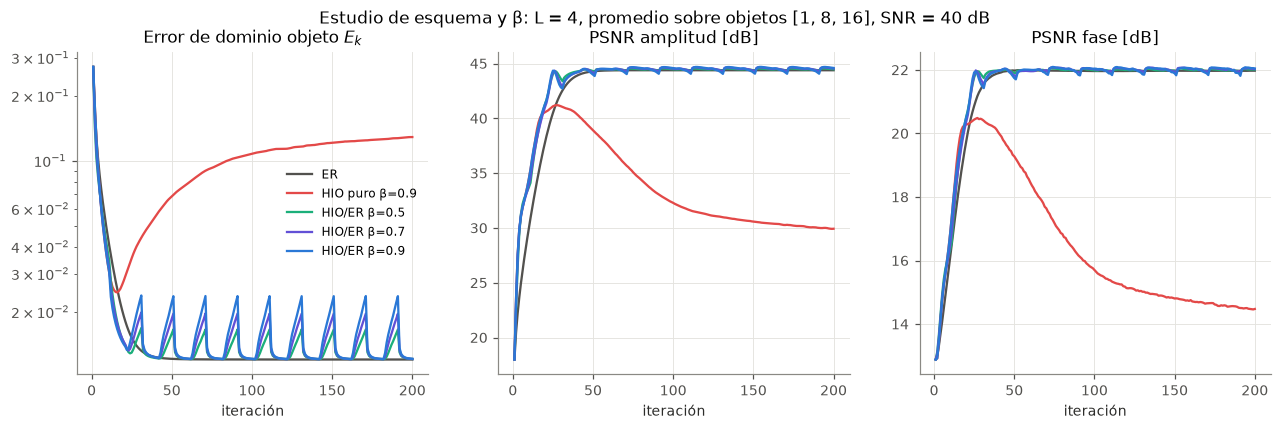

In [14]:
abl_colors = {"ER": "#52514e", "HIO puro β=0.9": "#e34948", "HIO/ER β=0.5": "#1baf7a",
              "HIO/ER β=0.7": "#6250d6", "HIO/ER β=0.9": "#2a78d6"}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
it = np.arange(1, ABL_ITERS + 1)
for name, runs in ablation.items():
    kw = dict(color=abl_colors[name], lw=1.5, label=name)
    axes[0].semilogy(it, np.mean([r["history"] for r in runs], 0), **kw)
    axes[1].plot(it, np.mean([r["curves"]["psnr_amp"] for r in runs], 0), **kw)
    axes[2].plot(it, np.mean([r["curves"]["psnr_ph"] for r in runs], 0), **kw)
axes[0].set_title("Error de dominio objeto $E_k$"); axes[1].set_title("PSNR amplitud [dB]"); axes[2].set_title("PSNR fase [dB]")
for ax in axes: ax.set_xlabel("iteración")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle(f"Estudio de esquema y β: L = 4, promedio sobre objetos {ABL_IMAGES}, SNR = {SNR_DB} dB")
fig.savefig(FIG_DIR / "beta_ablation.png"); plt.show()

**Resultados del estudio** ($L=4$, SNR = 40 dB, objetos 1, 8 y 16; ver la salida de la celda anterior):

* **ER** converge de forma monótona y estable, pero lenta: la PSNR de amplitud es ≈ 40.5 dB en la iteración 25
  y se estabiliza en ≈ 44.4 dB recién desde la iteración ~50.
* **HIO puro** ($\beta=0.9$) avanza rápido al comienzo, pero después **diverge**: la PSNR de amplitud baja a
  ≈ 32 dB en la iteración 100 y a ≈ 30 dB en la 200, mientras $E_k$ sube de ~2·10⁻² a ~0.13. Es el
  comportamiento conocido de HIO cuando el ruido hace inconsistentes las restricciones (Sección 6.3).
* **HIO/ER** (bloques 10+10) combina lo mejor de ambos: alcanza ≈ 44 dB ya en la iteración 25, casi el doble
  de rápido que ER, y se mantiene estable (44.5–44.6 dB entre 100 y 200 iteraciones). Los picos periódicos de
  $E_k$ corresponden a los bloques HIO, donde el iterado sale deliberadamente de $\mathcal S$. Cada bloque ER
  lo devuelve al conjunto.
* El valor de $\beta\in[0.5, 0.9]$ influye poco en el resultado final. $\beta=0.9$ (el valor clásico de Fienup)
  da la convergencia inicial más rápida y el valor final marginalmente mejor.

**Elección:** HIO/ER con $\beta=0.9$ y bloques 10+10, con **100 iteraciones totales** (5 ciclos, terminando en un
bloque ER). Desde la iteración ~50 la PSNR cambia menos de 0.3 dB, así que 100 iteraciones dejan margen de
convergencia para $L=4$ y $L=16$ con un costo bajo. Se usa un **número fijo** de iteraciones, y no un criterio
de parada por tolerancia, porque con ruido $E_k$ no tiende a 0 sino a un piso (~10⁻²) que depende del SNR y de
$L$. Así ambas configuraciones se comparan con el mismo presupuesto de iteraciones. Igual se reporta cuántas
iteraciones necesitó cada configuración para converger (Sección 11.3).

## 9. Experimentos con $L=4$

Pipeline completo para las 24 imágenes: objeto $\mathbf{O}_k$ → $L$ mediciones ruidosas → HIO
(`N_ITER` iteraciones, ciclos HIO/ER con `BETA`) → métricas de amplitud y fase. Se registran, por
iteración, $E_k$ y la PSNR, para estudiar la velocidad de convergencia.

In [15]:
def run_experiment(L, snr_db=SNR_DB, verbose=True):
    results = []
    t0 = time.perf_counter()
    for k in range(1, N_IMAGES + 1):
        r = run_one(k, L, N_ITER, BETA, snr_db=snr_db, track=True)
        results.append(r)
        m = r["metrics"]
        if verbose: print(f"L={L:2d} | k={k:2d} | amp PSNR={m['psnr_amp']:6.2f} SSIM={m['ssim_amp']:.4f} | "
              f"fase PSNR={m['psnr_ph']:6.2f} SSIM={m['ssim_ph']:.4f} | E_final={r['history'][-1]:.2e} | {r['time']:.1f}s")
    print(f"Tiempo total L={L} (SNR={snr_db}): {time.perf_counter() - t0:.1f} s")
    return results

def save_results(results, path):
    keys = ["psnr_amp", "ssim_amp", "psnr_ph", "ssim_ph"]
    arr = np.array([[r["k"], 25 - r["k"]] + [r["metrics"][q] for q in keys] + [r["time"], r["history"][-1]] for r in results])
    np.savetxt(path, arr, delimiter=",", fmt="%.6f",
               header="k_fase,k_amplitud," + ",".join(keys) + ",tiempo_s,E_final", comments="")

results = {}
results[4] = run_experiment(4)
save_results(results[4], RES_DIR / "metrics_L4.csv")

L= 4 | k= 1 | amp PSNR= 45.00 SSIM=0.9867 | fase PSNR= 27.32 SSIM=0.8497 | E_final=1.13e-02 | 1.5s


L= 4 | k= 2 | amp PSNR= 45.39 SSIM=0.9843 | fase PSNR= 23.49 SSIM=0.7674 | E_final=1.41e-02 | 1.8s


L= 4 | k= 3 | amp PSNR= 44.74 SSIM=0.9874 | fase PSNR= 31.53 SSIM=0.8822 | E_final=1.07e-02 | 1.5s


L= 4 | k= 4 | amp PSNR= 46.59 SSIM=0.9921 | fase PSNR= 27.18 SSIM=0.8634 | E_final=1.08e-02 | 1.4s


L= 4 | k= 5 | amp PSNR= 42.44 SSIM=0.9873 | fase PSNR= 28.35 SSIM=0.8713 | E_final=1.15e-02 | 1.4s


L= 4 | k= 6 | amp PSNR= 45.37 SSIM=0.9855 | fase PSNR= 16.25 SSIM=0.6630 | E_final=1.19e-02 | 1.4s


... (14 outputs left out)

L= 4 | k=21 | amp PSNR= 44.93 SSIM=0.9912 | fase PSNR= 33.47 SSIM=0.9176 | E_final=1.03e-02 | 1.4s


L= 4 | k=22 | amp PSNR= 46.65 SSIM=0.9892 | fase PSNR= 21.56 SSIM=0.8267 | E_final=1.10e-02 | 1.5s


L= 4 | k=23 | amp PSNR= 44.54 SSIM=0.9920 | fase PSNR= 33.55 SSIM=0.8565 | E_final=1.09e-02 | 1.5s


L= 4 | k=24 | amp PSNR= 42.67 SSIM=0.9832 | fase PSNR= 29.01 SSIM=0.8360 | E_final=1.12e-02 | 1.5s
Tiempo total L=4 (SNR=40): 36.0 s


## 10. Experimentos con $L=16$

Mismo pipeline, parámetros e iteraciones; solo cambia el conjunto de máscaras (8 pares complementarios).

In [16]:
results[16] = run_experiment(16)
save_results(results[16], RES_DIR / "metrics_L16.csv")

L=16 | k= 1 | amp PSNR= 52.37 SSIM=0.9975 | fase PSNR= 30.55 SSIM=0.9287 | E_final=1.48e-02 | 6.2s


L=16 | k= 2 | amp PSNR= 52.68 SSIM=0.9970 | fase PSNR= 30.04 SSIM=0.9032 | E_final=1.87e-02 | 5.3s


L=16 | k= 3 | amp PSNR= 52.06 SSIM=0.9976 | fase PSNR= 33.17 SSIM=0.9619 | E_final=1.40e-02 | 5.2s


L=16 | k= 4 | amp PSNR= 53.88 SSIM=0.9985 | fase PSNR= 28.81 SSIM=0.9339 | E_final=1.43e-02 | 5.2s


L=16 | k= 5 | amp PSNR= 49.74 SSIM=0.9976 | fase PSNR= 33.02 SSIM=0.9494 | E_final=1.52e-02 | 5.2s


L=16 | k= 6 | amp PSNR= 52.64 SSIM=0.9967 | fase PSNR= 17.07 SSIM=0.7558 | E_final=1.57e-02 | 5.3s


... (14 outputs left out)

L=16 | k=21 | amp PSNR= 52.16 SSIM=0.9983 | fase PSNR= 37.90 SSIM=0.9748 | E_final=1.36e-02 | 5.2s


L=16 | k=22 | amp PSNR= 53.97 SSIM=0.9980 | fase PSNR= 24.56 SSIM=0.9172 | E_final=1.46e-02 | 5.2s


L=16 | k=23 | amp PSNR= 51.79 SSIM=0.9985 | fase PSNR= 40.67 SSIM=0.9627 | E_final=1.45e-02 | 5.2s


L=16 | k=24 | amp PSNR= 49.95 SSIM=0.9968 | fase PSNR= 36.06 SSIM=0.9454 | E_final=1.49e-02 | 5.2s
Tiempo total L=16 (SNR=40): 127.5 s


## 11. Métricas y gráficos comparativos

### 11.1 Tabla resumen (promedio ± desviación estándar sobre las 24 imágenes)

In [17]:
KEYS = [("psnr_amp", "PSNR amplitud [dB]"), ("ssim_amp", "SSIM amplitud"),
        ("psnr_ph", "PSNR fase [dB]"), ("ssim_ph", "SSIM fase")]
metric = lambda L, key: np.array([r["metrics"][key] for r in results[L]])

rows = ["| Métrica | L = 4 | L = 16 |", "|---|---|---|"]
for key, name in KEYS:
    fmt = "{:.2f} ± {:.2f}" if "psnr" in key else "{:.4f} ± {:.4f}"
    rows.append(f"| {name} | " + " | ".join(fmt.format(metric(L, key).mean(), metric(L, key).std()) for L in L_LIST) + " |")
t_img = {L: np.array([r["time"] for r in results[L]]) for L in L_LIST}
rows.append("| Tiempo por imagen [s] | " + " | ".join(f"{t_img[L].mean():.2f}" for L in L_LIST) + " |")
rows.append("| Tiempo por iteración [ms] | " + " | ".join(f"{1e3 * t_img[L].mean() / N_ITER:.1f}" for L in L_LIST) + " |")
rows.append("| $E_k$ final (mediana) | " + " | ".join(f"{np.median([r['history'][-1] for r in results[L]]):.2e}" for L in L_LIST) + " |")
summary_md = "\n".join(rows)
display(Markdown(summary_md))
(RES_DIR / "summary.md").write_text(summary_md + "\n")

| Métrica | L = 4 | L = 16 |
|---|---|---|
| PSNR amplitud [dB] | 44.10 ± 1.94 | 51.39 ± 1.96 |
| SSIM amplitud | 0.9870 ± 0.0073 | 0.9974 ± 0.0015 |
| PSNR fase [dB] | 25.57 ± 5.75 | 29.10 ± 7.41 |
| SSIM fase | 0.8231 ± 0.0970 | 0.9038 ± 0.0806 |
| Tiempo por imagen [s] | 1.48 | 5.27 |
| Tiempo por iteración [ms] | 14.8 | 52.7 |
| $E_k$ final (mediana) | 1.11e-02 | 1.47e-02 |

381

### 11.2 PSNR y SSIM por imagen ($L=4$ vs $L=16$)

En el eje $x$ está el índice $k$ del objeto (fase = imagen $k$, amplitud = imagen $25-k$).

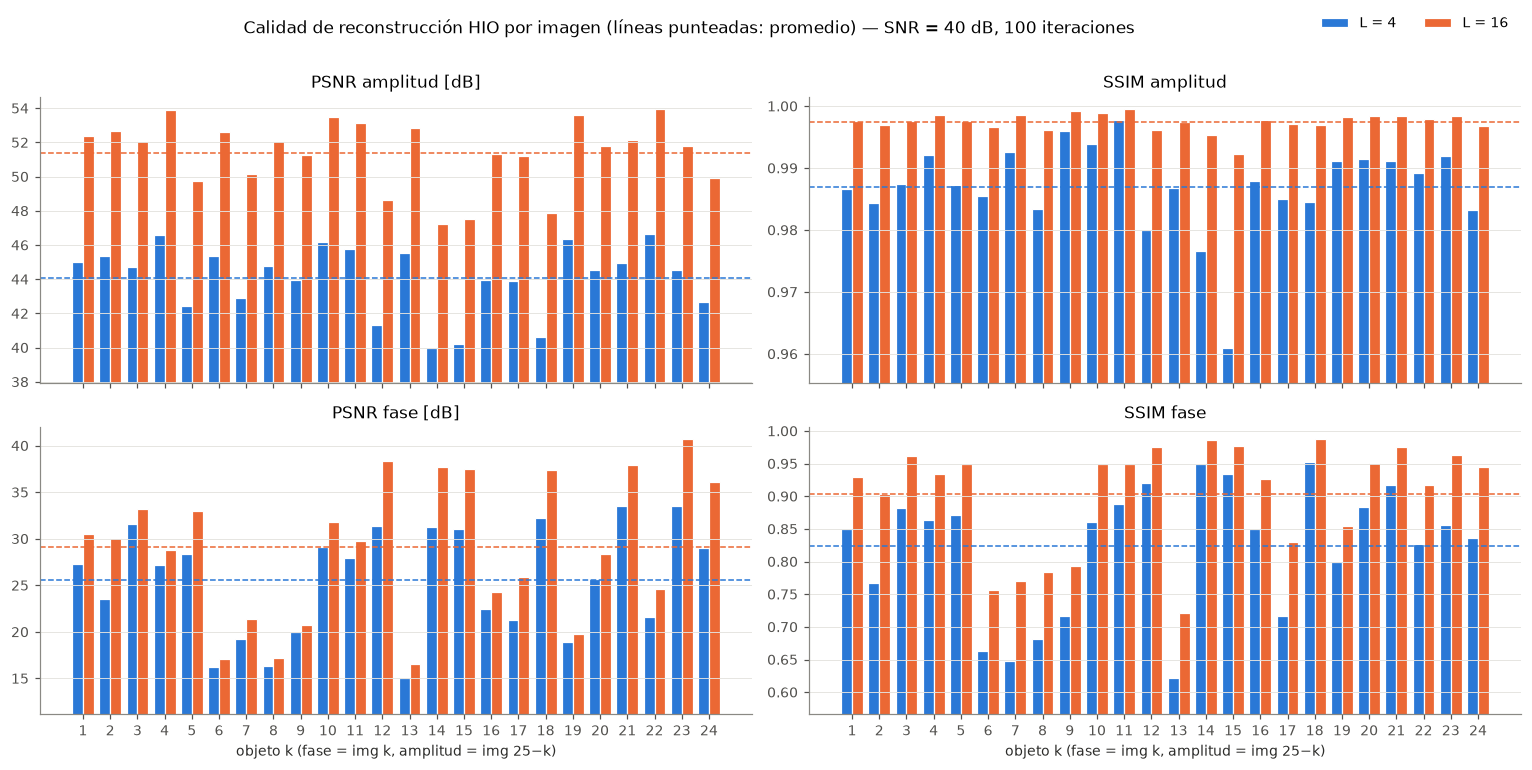

In [18]:
ks = np.arange(1, N_IMAGES + 1)
w = 0.4
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)
for ax, (key, name) in zip(axes.flat, KEYS):
    for j, L in enumerate(L_LIST):
        ax.bar(ks + (j - 0.5) * w, metric(L, key), width=w, color=COLORS[L],
               edgecolor="white", linewidth=0.8, label=f"L = {L}")
        ax.axhline(metric(L, key).mean(), color=COLORS[L], lw=1, ls="--")
    ax.set_title(name); ax.set_xticks(ks)
    lo = min(metric(L, key).min() for L in L_LIST); hi = max(metric(L, key).max() for L in L_LIST)
    ax.set_ylim(max(0, lo - 0.15 * (hi - lo)), hi + 0.05 * (hi - lo))
    ax.grid(axis="x", visible=False)
for ax in axes[1]: ax.set_xlabel("objeto k (fase = img k, amplitud = img 25−k)")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, ncol=2, loc="upper right", bbox_to_anchor=(0.99, 1.0))
fig.suptitle(f"Calidad de reconstrucción HIO por imagen (líneas punteadas: promedio) — SNR = {SNR_DB} dB, {N_ITER} iteraciones",
             x=0.45)
fig.tight_layout(rect=(0, 0, 1, 0.97)); fig.savefig(FIG_DIR / "metrics_per_image.png"); plt.show()

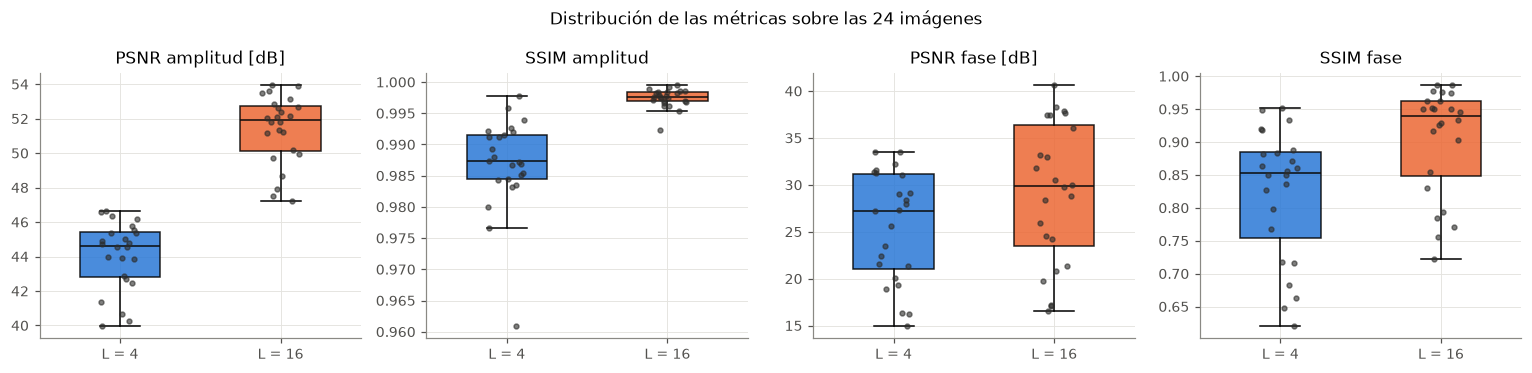

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, (key, name) in zip(axes, KEYS):
    data = [metric(L, key) for L in L_LIST]
    bp = ax.boxplot(data, patch_artist=True, widths=0.5, showfliers=False, medianprops=dict(color="#0b0b0b"))
    for patch, L in zip(bp["boxes"], L_LIST):
        patch.set_facecolor(COLORS[L]); patch.set_alpha(0.85)
    for j, (L, d) in enumerate(zip(L_LIST, data)):
        ax.scatter(np.full(d.size, j + 1) + np.random.default_rng(j).uniform(-0.12, 0.12, d.size), d,
                   s=10, color="#2c2c2a", alpha=0.6, zorder=3)
    ax.set_xticks([1, 2], [f"L = {L}" for L in L_LIST]); ax.set_title(name)
fig.suptitle("Distribución de las métricas sobre las 24 imágenes")
fig.tight_layout(); fig.savefig(FIG_DIR / "metrics_boxplot.png"); plt.show()

### 11.3 Convergencia del HIO ($L=4$ vs $L=16$)

Curva mediana sobre las 24 imágenes, con banda entre los percentiles 10 y 90. Las franjas grises marcan
los bloques de ER.

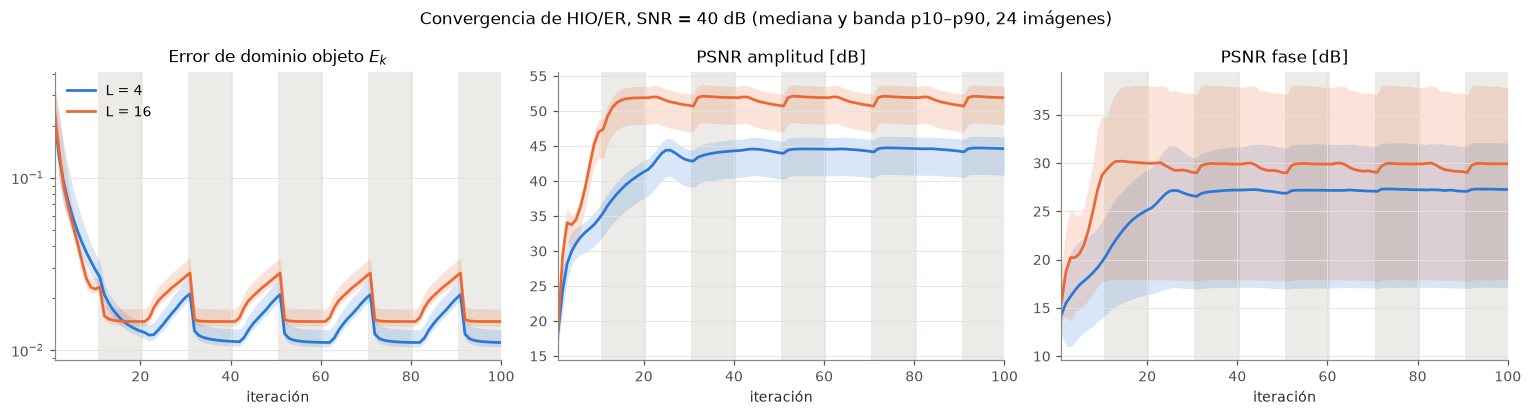

Iteraciones hasta quedar a 0.5 dB de la PSNR final (psnr_amp): L=4: mediana 25, máx 25, L=16: mediana 15, máx 16
Iteraciones hasta quedar a 0.5 dB de la PSNR final (psnr_ph): L=4: mediana 24, máx 25, L=16: mediana 12, máx 15


In [20]:
def plot_convergence(res, title, fname):
    it = np.arange(1, N_ITER + 1)
    sched = hio_schedule(N_ITER, HIO_BLOCK, ER_BLOCK)
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
    series = [("history", "Error de dominio objeto $E_k$", True),
              ("psnr_amp", "PSNR amplitud [dB]", False), ("psnr_ph", "PSNR fase [dB]", False)]
    for ax, (key, ttl, logy) in zip(axes, series):
        for s0 in np.flatnonzero(np.diff(np.r_[True, sched].astype(int)) == -1):
            ax.axvspan(s0 + 0.5, s0 + ER_BLOCK + 0.5, color="#ecebe7", lw=0, zorder=0)
        for L in L_LIST:
            curves = np.array([r["history"] if key == "history" else r["curves"][key] for r in res[L]])
            med, p10, p90 = np.median(curves, 0), np.percentile(curves, 10, 0), np.percentile(curves, 90, 0)
            ax.plot(it, med, color=COLORS[L], lw=1.8, label=f"L = {L}")
            ax.fill_between(it, p10, p90, color=COLORS[L], alpha=0.18, lw=0)
        if logy: ax.set_yscale("log")
        ax.set_title(ttl); ax.set_xlabel("iteración"); ax.set_xlim(1, N_ITER)
    axes[0].legend(frameon=False)
    fig.suptitle(title)
    fig.tight_layout(); fig.savefig(FIG_DIR / fname); plt.show()

def iters_to_converge(res, L, key="psnr_amp", tol_db=0.5):
    # Primera iteración en que la PSNR queda a menos de tol_db del valor final.
    out = []
    for r in res[L]:
        c = np.asarray(r["curves"][key])
        out.append(np.argmax(c >= c[-1] - tol_db) + 1)
    return np.array(out)

plot_convergence(results, f"Convergencia de HIO/ER, SNR = {SNR_DB} dB (mediana y banda p10–p90, 24 imágenes)", "convergence.png")
for key in ["psnr_amp", "psnr_ph"]:
    print(f"Iteraciones hasta quedar a 0.5 dB de la PSNR final ({key}): " +
          ", ".join(f"L={L}: mediana {np.median(iters_to_converge(results, L, key)):.0f}, "
                    f"máx {iters_to_converge(results, L, key).max()}" for L in L_LIST))

### 11.4 Ejemplos visuales

Tres objetos: el de mejor PSNR media de fase, el mediano y el peor (según $L=4$). Para cada uno se muestra
el *ground truth* y las reconstrucciones con $L=4$ y $L=16$ (amplitud y fase), además del error absoluto de fase.

Objetos mostrados (k): [np.int64(23), np.int64(1), np.int64(13)]


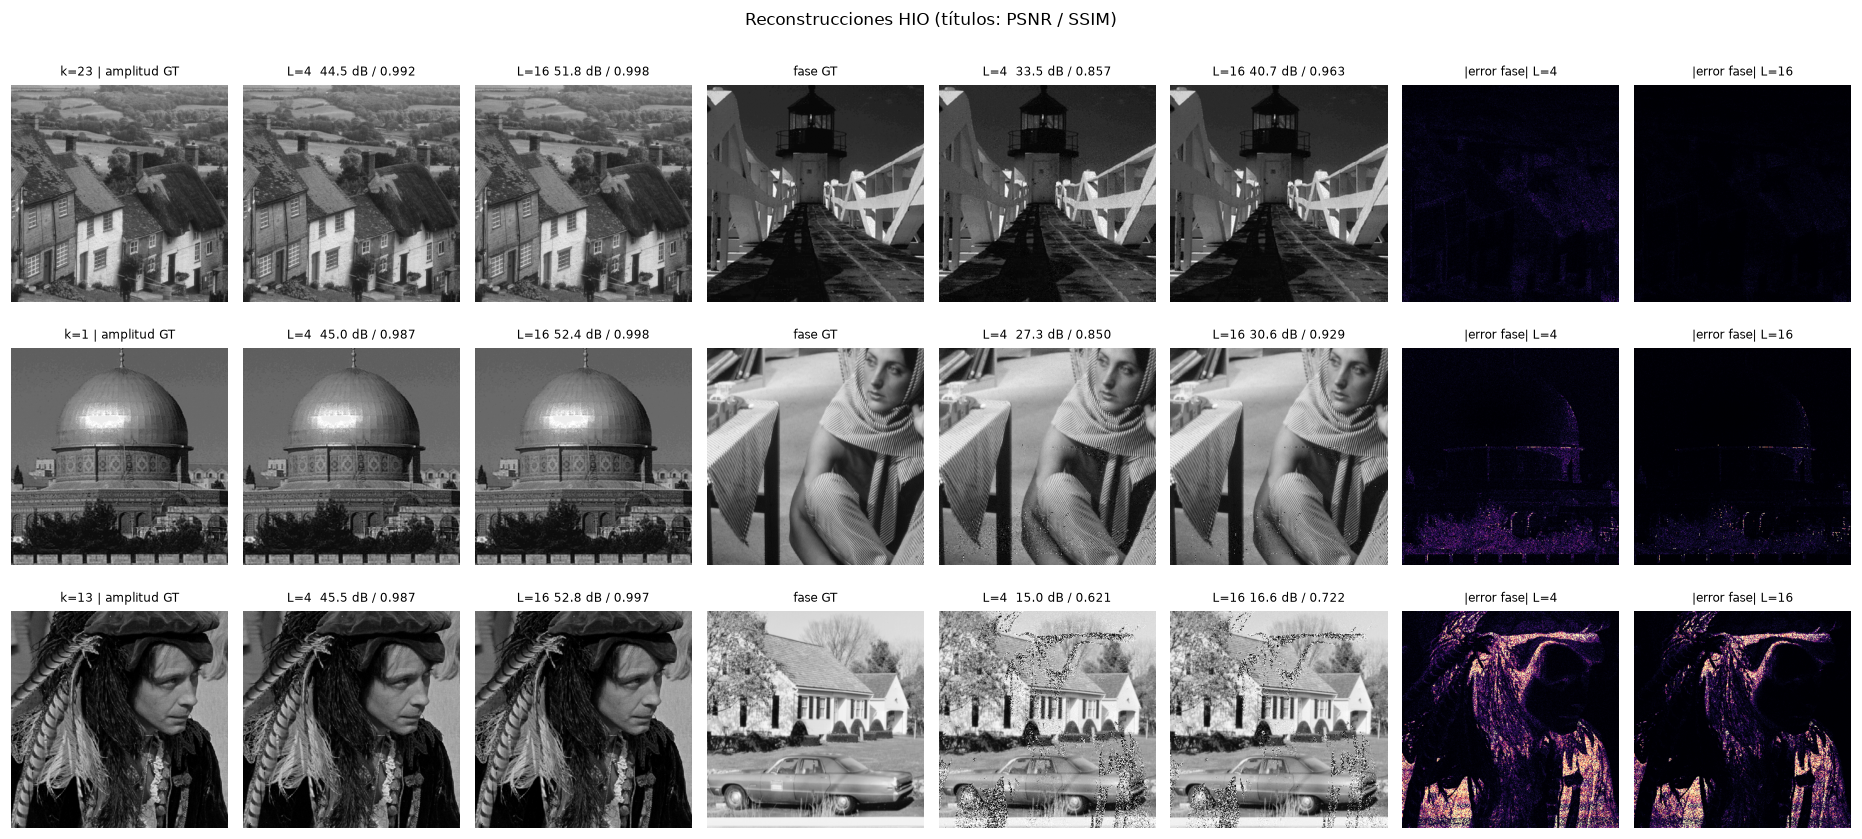

In [21]:
order = np.argsort(metric(4, "psnr_ph"))
examples = [order[-1] + 1, order[len(order) // 2] + 1, order[0] + 1]
print("Objetos mostrados (k):", examples)

fig, axes = plt.subplots(len(examples), 8, figsize=(17, 2.4 * len(examples) + 0.6))
for row, k in enumerate(examples):
    amplitude, phase, _ = make_object(dataset, k)
    r4, r16 = results[4][k - 1], results[16][k - 1]
    panels = [
        (amplitude, f"k={k} | amplitud GT", "gray", (0, 1)),
        (r4["amp_hat"], f"L=4  {r4['metrics']['psnr_amp']:.1f} dB / {r4['metrics']['ssim_amp']:.3f}", "gray", (0, 1)),
        (r16["amp_hat"], f"L=16 {r16['metrics']['psnr_amp']:.1f} dB / {r16['metrics']['ssim_amp']:.3f}", "gray", (0, 1)),
        (phase, "fase GT", "gray", (0, 1)),
        (r4["ph_hat"], f"L=4  {r4['metrics']['psnr_ph']:.1f} dB / {r4['metrics']['ssim_ph']:.3f}", "gray", (0, 1)),
        (r16["ph_hat"], f"L=16 {r16['metrics']['psnr_ph']:.1f} dB / {r16['metrics']['ssim_ph']:.3f}", "gray", (0, 1)),
        (np.abs(r4["ph_hat"] - phase), "|error fase| L=4", "magma", (0, 0.5)),
        (np.abs(r16["ph_hat"] - phase), "|error fase| L=16", "magma", (0, 0.5)),
    ]
    for ax, (im, title, cmap, (vmin, vmax)) in zip(axes[row], panels):
        ax.imshow(im, cmap=cmap, vmin=vmin, vmax=vmax); ax.set_title(title, fontsize=8); ax.axis("off")
fig.suptitle("Reconstrucciones HIO (títulos: PSNR / SSIM)", y=1.0)
fig.tight_layout(); fig.savefig(FIG_DIR / "visual_examples.png"); plt.show()

### 11.5 ¿Dónde falla la fase? Relación con la amplitud

La fase solo es observable donde hay luz. La figura relaciona el error de fase por píxel con la amplitud
real, agregando todos los objetos.

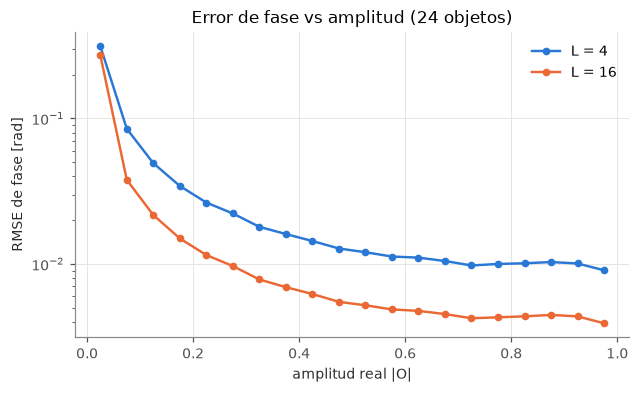

In [22]:
bins = np.linspace(0, 1, 21)
centers = 0.5 * (bins[1:] + bins[:-1])
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for L in L_LIST:
    num = np.zeros(len(centers)); den = np.zeros(len(centers))
    for r in results[L]:
        amplitude, phase, _ = make_object(dataset, r["k"])
        idx = np.clip(np.digitize(amplitude.ravel(), bins) - 1, 0, len(centers) - 1)
        num += np.bincount(idx, weights=((r["ph_hat"] - phase) ** 2).ravel(), minlength=len(centers))
        den += np.bincount(idx, minlength=len(centers))
    ax.semilogy(centers, np.sqrt(num / np.maximum(den, 1)), "o-", color=COLORS[L], ms=4, lw=1.6, label=f"L = {L}")
ax.set_xlabel("amplitud real |O|"); ax.set_ylabel("RMSE de fase [rad]")
ax.set_title("Error de fase vs amplitud (24 objetos)"); ax.legend(frameon=False)
fig.savefig(FIG_DIR / "phase_error_vs_amplitude.png"); plt.show()

### 11.6 Experimento complementario sin ruido ($\boldsymbol\Omega=0$)

Mismo pipeline sin ruido. Aísla el efecto de $L$ sobre la **velocidad de convergencia**: sin ruido, el
problema es consistente y el error puede llegar a cero, de modo que la calidad final queda limitada solo por
el número de iteraciones y, en la fase, por los píxeles de amplitud nula. Se reportan medianas y rangos
porque la PSNR puede ser enorme (> 200 dB) en reconstrucciones casi exactas, lo que distorsiona la media.

Tiempo total L=4 (SNR=None): 32.1 s


Tiempo total L=16 (SNR=None): 126.6 s


| Métrica (sin ruido), mediana (mín – máx) | L = 4 | L = 16 |
|---|---|---|
| PSNR amplitud [dB] | 87.09 (81.77 – 89.96) | 235.54 (223.04 – 237.89) |
| SSIM amplitud | 1.0000 (1.0000 – 1.0000) | 1.0000 (1.0000 – 1.0000) |
| PSNR fase [dB] | 31.54 (17.33 – 76.18) | 31.83 (17.43 – 224.52) |
| SSIM fase | 0.9794 (0.8134 – 1.0000) | 0.9810 (0.8162 – 1.0000) |
| $E_k$ final (mediana) | 4.19e-05 | 3.24e-12 |
| Iteraciones hasta PSNR amp ≥ 40 dB (mediana; n° imágenes que lo logran) | 15 (24/24) | 8 (24/24) |
| Iteraciones hasta PSNR amp ≥ 60 dB (mediana; n° imágenes que lo logran) | 34 (24/24) | 15 (24/24) |
| Iteraciones hasta PSNR amp ≥ 100 dB (mediana; n° imágenes que lo logran) | 86 (10/24) | 34 (24/24) |

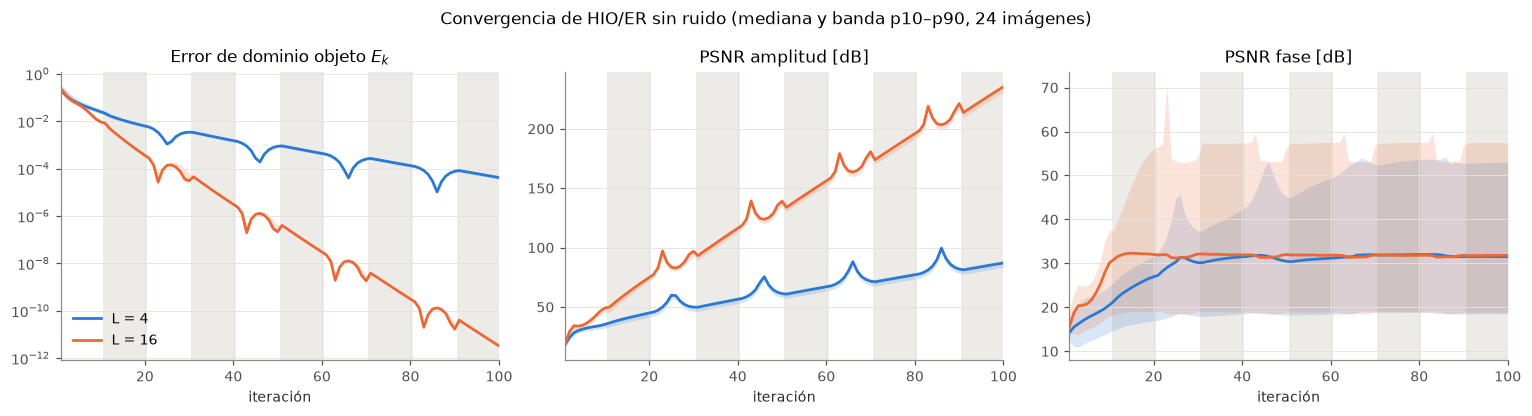

In [23]:
if RUN_NOISELESS:
    results_clean = {L: run_experiment(L, snr_db=None, verbose=False) for L in L_LIST}
    for L in L_LIST:
        save_results(results_clean[L], RES_DIR / f"metrics_L{L}_sin_ruido.csv")
    mclean = lambda L, key: np.array([r["metrics"][key] for r in results_clean[L]])
    rows = ["| Métrica (sin ruido), mediana (mín – máx) | L = 4 | L = 16 |", "|---|---|---|"]
    for key, name in KEYS:
        fmt = "{:.2f} ({:.2f} – {:.2f})" if "psnr" in key else "{:.4f} ({:.4f} – {:.4f})"
        rows.append(f"| {name} | " + " | ".join(fmt.format(np.median(mclean(L, key)), mclean(L, key).min(), mclean(L, key).max())
                                                for L in L_LIST) + " |")
    rows.append("| $E_k$ final (mediana) | " + " | ".join(f"{np.median([r['history'][-1] for r in results_clean[L]]):.2e}" for L in L_LIST) + " |")
    for tgt in (40, 60, 100):
        def first_reach(L, t=tgt):
            v = [np.argmax(np.asarray(r["curves"]["psnr_amp"]) >= t) + 1 if max(r["curves"]["psnr_amp"]) >= t else np.nan
                 for r in results_clean[L]]
            return np.nanmedian(v), np.isfinite(v).sum()
        rows.append(f"| Iteraciones hasta PSNR amp ≥ {tgt} dB (mediana; n° imágenes que lo logran) | " +
                    " | ".join("{:.0f} ({}/24)".format(*first_reach(L)) for L in L_LIST) + " |")
    clean_md = "\n".join(rows)
    display(Markdown(clean_md))
    (RES_DIR / "summary_sin_ruido.md").write_text(clean_md + "\n")
    plot_convergence(results_clean, "Convergencia de HIO/ER sin ruido (mediana y banda p10–p90, 24 imágenes)",
                     "convergence_sin_ruido.png")

## 12. Conclusiones

Resultados principales (SNR = 40 dB, 100 iteraciones HIO/ER con $\beta=0.9$, 24 objetos, imágenes de 384×384):

| | $L=4$ | $L=16$ |
|---|---|---|
| PSNR / SSIM amplitud | 44.10 dB / 0.987 | 51.39 dB / 0.997 |
| PSNR / SSIM fase | 25.57 dB / 0.823 | 29.10 dB / 0.904 |
| Iteraciones hasta converger (a 0.5 dB de la PSNR final, mediana) | 25 | 15 |
| Tiempo por iteración / por imagen | 14.8 ms / 1.5 s | 52.7 ms / 5.3 s |

1. **Calidad de reconstrucción.** $L=16$ supera a $L=4$ en **las 24 imágenes y en las 4 métricas**. En
   amplitud, la ganancia es de +7.3 dB en PSNR y es muy uniforme entre imágenes (entre +7.2 y +7.4 dB); el
   SSIM sube de 0.987 a 0.997. En fase, la ganancia es de +3.5 dB en PSNR (entre +0.8 y +7.1 dB) y de +0.08 en
   SSIM. Con máscaras complementarias, cada píxel se observa en $L/2$ mediciones (2 contra 8). Al cuadruplicar
   la redundancia con el mismo SNR por medición, el ruido se promedia: lo esperable es ≈ 6 dB
   ($10\log_{10}4$), y se observa algo más. El RMSE de fase en zonas bien iluminadas baja de ≈ 0.010 rad a
   ≈ 0.0045 rad (Sección 11.5).

2. **La fase es la componente difícil y está limitada por la amplitud.** En los píxeles donde $|\mathbf O|\approx0$,
   la fase no es observable: allí el RMSE es ≈ 0.3 rad tanto con $L=4$ como con $L=16$. Esto explica la gran
   dispersión de la PSNR de fase (15–40 dB) y que los objetos cuya amplitud tiene muchas zonas oscuras
   ($k$ = 6, 8, 13, con amplitudes 19, 17 y 12) queden bajo 18 dB incluso con $L=16$. Aumentar $L$ no
   resuelve esta limitación, porque es física y no del sistema de medición. Sin ruido, la fase se recupera casi exactamente (> 200 dB con $L=16$) solo en los objetos
   cuya amplitud no se anula. La mediana de PSNR de fase sin ruido (≈ 31.5 dB) es casi igual para ambos $L$,
   lo que confirma que el límite es el objeto y no el número de máscaras.

3. **Velocidad de convergencia.** Con más máscaras, el problema está más restringido y HIO converge en menos
   iteraciones:
   * con ruido, $L=16$ queda a 0.5 dB de su PSNR final en 15 iteraciones, contra 25 para $L=4$;
   * sin ruido (Sección 11.6), $L=16$ supera los 60 dB de amplitud en 15 iteraciones (contra 34) y los
     100 dB en 34 iteraciones en las 24 imágenes. Con $L=4$, en cambio, solo 10 de 24 imágenes llegan a
     100 dB dentro de las 100 iteraciones. Al final, $E_k$ llega a ~10⁻¹² con $L=16$ (precisión de máquina)
     y a ~10⁻⁵ con $L=4$.

4. **Costo computacional.** El costo por iteración crece de forma aproximadamente lineal con $L$ (≈ 3.6× más: 52.7 ms contra 14.8 ms),
   porque cada iteración propaga y retropropaga las $L$ ondas. Medido en tiempo hasta converger, $L=4$ es más
   barato (≈ 25 × 14.8 ms ≈ 0.37 s contra ≈ 15 × 52.7 ms ≈ 0.79 s; los tiempos absolutos dependen del equipo), pero se estanca en una calidad bastante menor.
   Además, $L=16$ requiere adquirir 4 veces más mediciones con el DMD. Es la disyuntiva clásica entre calidad
   y tiempo de adquisición y cómputo.

5. **Estabilidad del HIO.** Con datos ruidosos, HIO puro **diverge** para ambos $L$, porque el término de
   realimentación acumula la inconsistencia del ruido. Alternar bloques HIO/ER (Fienup) lo vuelve estable y,
   además, alcanza el nivel final casi el doble de rápido que ER puro (equivalente a `PhaseLiftSimu.m`). El
   piso de $E_k$ es algo mayor con $L=16$ (1.5·10⁻² contra 1.1·10⁻²) aunque la reconstrucción es mejor: $E_k$
   mide la inconsistencia entre más mediciones ruidosas, no el error respecto del *ground truth*. Sin ruido,
   ambos tienden a 0.

6. **Observaciones de implementación.** El propagador de espectro angular portado de MATLAB coincide con el
   original a ~10⁻¹⁴, es unitario y su inversa (propagar con $-z$) es exacta. Con los parámetros de `main.m`,
   el tamaño de 384×384 cumple el criterio de muestreo $N\ge\lambda\Delta z/\delta^2\approx257$, que 256×256
   habría violado. El número de condición de `ComputeConditionNumber.m` es infinito en la práctica para
   máscaras complementarias con $L\ge4$, por la dependencia lineal de los pares, de modo que no es un buen
   indicador del condicionamiento de este problema de phase retrieval, que es no lineal.

**En resumen:** con máscaras aleatorias complementarias y HIO/ER, $L=4$ ya recupera la amplitud con alta
fidelidad (> 40 dB, SSIM ≈ 0.99). Pasar a $L=16$ mejora la amplitud en ≈ 7 dB y la fase en ≈ 3.5 dB, y
reduce las iteraciones necesarias (de 25 a 15 con ruido, y a menos de la mitad sin ruido), a cambio de 4 veces más mediciones y ≈ 3.6 veces más cómputo por
iteración. La principal limitación restante, la fase en zonas de amplitud casi nula, es intrínseca al objeto
y no depende de $L$.

## 13. Anexo: comparaciones visuales de las 24 reconstrucciones

Se generan láminas con 4 objetos cada una (filas). Las columnas muestran, de izquierda a derecha: amplitud
real, amplitud con $L=4$, amplitud con $L=16$, fase real, fase con $L=4$ y fase con $L=16$ (SNR = 40 dB). Se
guardan en `Fig/anexo_comparaciones_XX_YY.png` para el informe y aquí se muestra solo la primera.

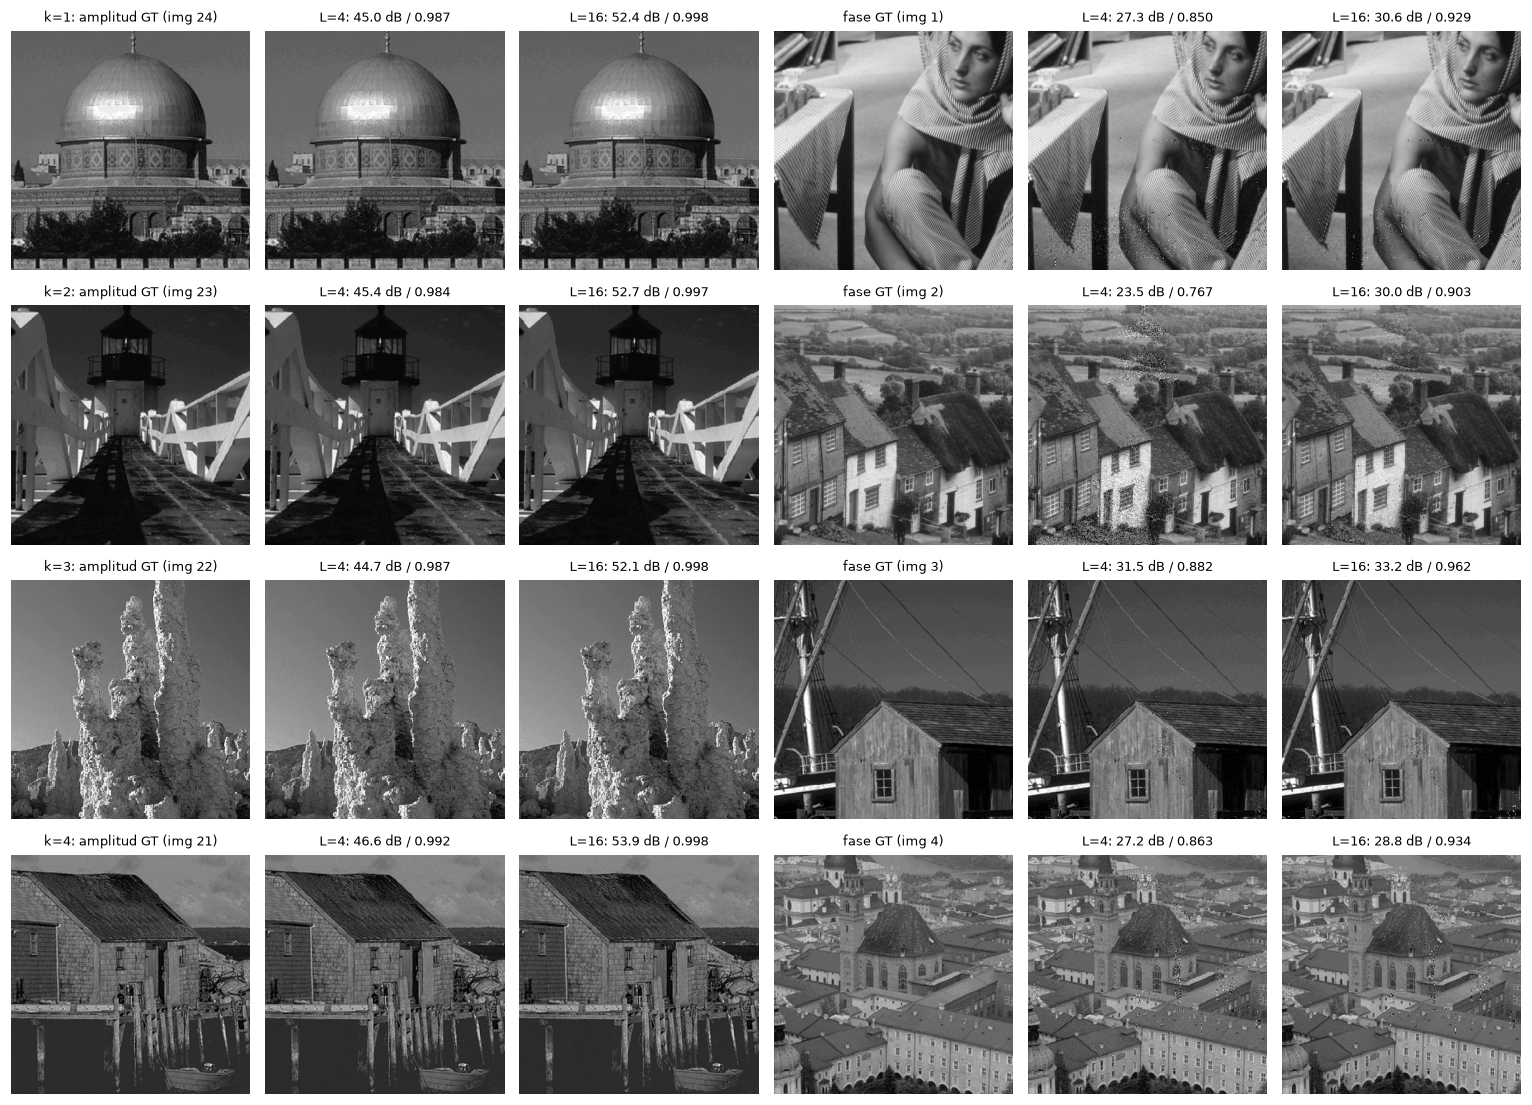

guardado: Fig/anexo_comparaciones_01_04.png


guardado: Fig/anexo_comparaciones_05_08.png


guardado: Fig/anexo_comparaciones_09_12.png


guardado: Fig/anexo_comparaciones_13_16.png


guardado: Fig/anexo_comparaciones_17_20.png


guardado: Fig/anexo_comparaciones_21_24.png


In [24]:
for start in range(1, N_IMAGES + 1, 4):
    ks_page = list(range(start, min(start + 4, N_IMAGES + 1)))
    fig, axes = plt.subplots(len(ks_page), 6, figsize=(14, 2.55 * len(ks_page)))
    for row, k in enumerate(ks_page):
        amplitude, phase, _ = make_object(dataset, k)
        r4, r16 = results[4][k - 1], results[16][k - 1]
        m4, m16 = r4["metrics"], r16["metrics"]
        panels = [(amplitude, f"k={k}: amplitud GT (img {25 - k})"),
                  (r4["amp_hat"], f"L=4: {m4['psnr_amp']:.1f} dB / {m4['ssim_amp']:.3f}"),
                  (r16["amp_hat"], f"L=16: {m16['psnr_amp']:.1f} dB / {m16['ssim_amp']:.3f}"),
                  (phase, f"fase GT (img {k})"),
                  (r4["ph_hat"], f"L=4: {m4['psnr_ph']:.1f} dB / {m4['ssim_ph']:.3f}"),
                  (r16["ph_hat"], f"L=16: {m16['psnr_ph']:.1f} dB / {m16['ssim_ph']:.3f}")]
        for ax, (im, title) in zip(axes[row], panels):
            ax.imshow(im, cmap="gray", vmin=0, vmax=1); ax.set_title(title, fontsize=8.5); ax.axis("off")
    fig.tight_layout()
    path = FIG_DIR / f"anexo_comparaciones_{ks_page[0]:02d}_{ks_page[-1]:02d}.png"
    fig.savefig(path)
    if start == 1:
        plt.show()
    else:
        plt.close(fig)
    print("guardado:", path)